# **Proyecto Citas Médicas**

Objetivos:
* Desarrollar un modelo de selección de factores para identificar las variables más relevantes en la predicción del estado de una cita médica.
* Desarrollar un modelo descriptivo tipo clustering para identificar perfiles de pacientes y citas mediante sus características, como apoyo a la predicción del estado de la cita.
* Desarrollar un modelo predictivo de clasificación para predecir si un paciente asistirá, no asistirá o cancelará una cita médica programada.

Integrantes
* Paola Andrea Duque Zuluaga
* Katerin Giraldo Betancur
* hon Edisson Hurtado Ocampo

In [1]:
#Cargamos librerías principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff

# 1. Preparación de Datos

In [2]:
#Cargamos los datos
data = pd.read_csv("reporte_citas_medicas.csv", quotechar="'")
data.head()

,oportunidad,sexopaciente,programacronico,funcionalidad,rotulo,municipiosede,turno_doble,poblacion_vulnerable,grupo_convenionombre,grupo_municipio,dia_semana,mes,grupo_horacita,grupo_edad,grupo_pym,grupo_codigocups,estado_cita
0,112,M,Nefroproteccion,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,LUNES,JULIO,MADRUGADA,VEJEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,ACTIVO
1,93,M,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MADRUGADA,VEJEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,ACTIVO
2,92,F,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MADRUGADA,VEJEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,CITA CANCELADA
3,92,F,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,mas de 6 horas,MIERCOLES,JULIO,MADRUGADA,VEJEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,ACTIVO
4,91,F,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MADRUGADA,ADULTEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,INCUMPLIDO


In [3]:
#Conocemos los datos
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56411 entries, 0 to 56410
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   oportunidad           56411 non-null  int64 
 1   sexopaciente          56411 non-null  object
 2   programacronico       56411 non-null  object
 3   funcionalidad         56411 non-null  object
 4   rotulo                56411 non-null  object
 5   municipiosede         56411 non-null  object
 6   turno_doble           56411 non-null  object
 7   poblacion_vulnerable  56411 non-null  object
 8   grupo_convenionombre  56411 non-null  object
 9   grupo_municipio       56411 non-null  object
 10  dia_semana            56411 non-null  object
 11  mes                   56411 non-null  object
 12  grupo_horacita        56411 non-null  object
 13  grupo_edad            56411 non-null  object
 14  grupo_pym             56411 non-null  object
 15  grupo_codigocups      56411 non-null

In [4]:
#Corrección tipos de datos
data['sexopaciente']=data['sexopaciente'].astype('category')
data['programacronico']=data['programacronico'].astype('category')
data['funcionalidad']=data['funcionalidad'].astype('category')
data['rotulo']=data['rotulo'].astype('category')
data['municipiosede']=data['municipiosede'].astype('category')
data['turno_doble']=data['turno_doble'].astype('category')
data['poblacion_vulnerable']=data['poblacion_vulnerable'].astype('category')
data['grupo_convenionombre']=data['grupo_convenionombre'].astype('category')
data['grupo_municipio']=data['grupo_municipio'].astype('category')
data['dia_semana']=data['dia_semana'].astype('category')
data['mes']=data['mes'].astype('category')
data['grupo_horacita']=data['grupo_horacita'].astype('category')
data['grupo_edad']=data['grupo_edad'].astype('category')
data['grupo_pym']=data['grupo_pym'].astype('category')
data['grupo_codigocups']=data['grupo_codigocups'].astype('category')
data['estado_cita']=data['estado_cita'].astype('category')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56411 entries, 0 to 56410
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   oportunidad           56411 non-null  int64   
 1   sexopaciente          56411 non-null  category
 2   programacronico       56411 non-null  category
 3   funcionalidad         56411 non-null  category
 4   rotulo                56411 non-null  category
 5   municipiosede         56411 non-null  category
 6   turno_doble           56411 non-null  category
 7   poblacion_vulnerable  56411 non-null  category
 8   grupo_convenionombre  56411 non-null  category
 9   grupo_municipio       56411 non-null  category
 10  dia_semana            56411 non-null  category
 11  mes                   56411 non-null  category
 12  grupo_horacita        56411 non-null  category
 13  grupo_edad            56411 non-null  category
 14  grupo_pym             56411 non-null  category
 15  gr

In [5]:
#Descripción de variables numéricas
data.describe()

,oportunidad
count,56411.000000
mean,15.288809
std,20.391272
min,0.000000
25%,2.000000
50%,7.000000
75%,20.000000
max,150.000000


<Axes: >

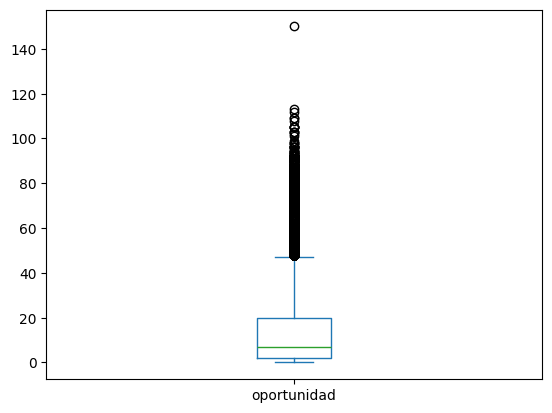

In [6]:
data.plot(kind='box')

<Axes: xlabel='estado_cita'>

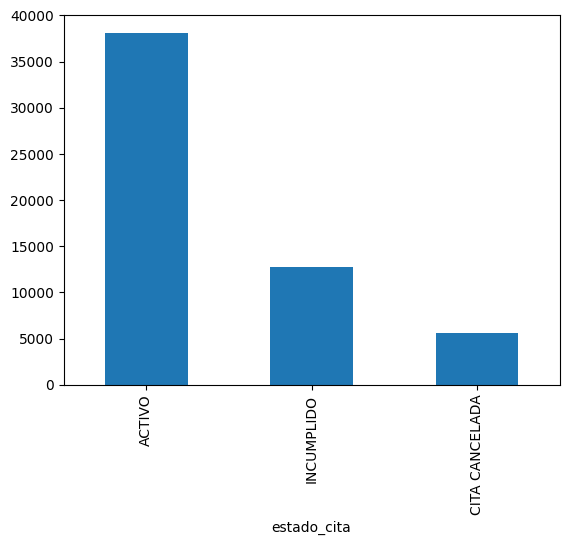

In [7]:
#Descripción variables categóricas (objetivo)
data['estado_cita'].value_counts().plot(kind='bar')

In [8]:
# Instalar pandas profiling
!pip install ydata-profiling

In [9]:
# Cargar librería para Profiling
from pandas_profiling import ProfileReport

profile_data=ProfileReport(data, minimal=False) # minimal=True
profile_data

/tmp/ipykernel_7898/2390340134.py:2: DeprecationWarning: `import pandas_profiling` is going to be deprecated by April 1st. Please use `import ydata_profiling` instead.
  from pandas_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 17/17 [00:02<00:00,  7.61it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [10]:
#Guardamos en html el perfilado de datos
profile_data.to_file(output_file="output.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [11]:

#Duplicados: Se conservan, ya que la anonimización y agrupación de variables  generó registros idénticos correspondientes a citas diferentes.
#Valores cero: Se conservan, pues oportunidad = 0 representa citas asignadas para el mismo día y es un valor válido.
#Variables desbalanceadas: Se conserva su distribución original, ya que responde a características propias de los datos y no constituye necesariamente un error de calidad.



In [12]:
#Validación concurrencia entre funcionalidad y grupo_codigocups --> hay asociación alta pero no redundancia
pd.crosstab(data['funcionalidad'], data['grupo_codigocups'])

grupo_codigocups,CONSULTAS CLINICAS Y OTROS PROFESIONALES,LABORATORIO CLINICO,ODONTOLOGIA ESPECIALIZADA,ODONTOLOGIA GENERAL Y PREVENTIVA,PATOLOGIA,PROCEDIMIENTOS DE ENFERMERIA,TERAPIAS Y REHABILITACION
funcionalidad,,,,,,,
CONSULTA,24865,12,27,410,0,78,0
LABORATORIO,0,11361,0,0,0,0,0
PROCEDIMIENTO,4692,281,6,0,326,315,0
TERAPIAS,688,0,0,0,0,0,13022
TRATAMIENTO ODONTOLOGICO,0,0,328,0,0,0,0


In [13]:
#validación concurrencia entre rotulo y funcionalidad --> hay asociación alta pero no redundancia
pd.crosstab(data['funcionalidad'], data['rotulo'])

rotulo,AGENDAMIENTO LABORATORIO CLINICO,AGENDAMIENTO PATOLOGIA,CAMBIO DE SONDA,CONSULTA PRIMERA VEZ ODONTOLOGIA,CONSULTA TRATAMIENTO ODONTOLOGIA,MONITOREO FETAL,MONITOREO PRESION ARTERIAL,PROCEDIMIENTOS COLPOSCOPIA,PROCEDIMIENTOS DE ELECTROCARDIOGRAMA,PROCEDIMIENTOS MENORES ENFERMERIA,SIN ROTULO,TOMA DE MUESTRAS DOMICILIARIAS
funcionalidad,,,,,,,,,,,,
CONSULTA,8,0,0,1,16,0,0,1,2,0,25364,0
LABORATORIO,10752,0,0,0,0,0,0,0,0,0,569,40
PROCEDIMIENTO,1,326,1,0,4,131,95,232,3182,368,1280,0
TERAPIAS,0,0,0,0,0,0,0,0,0,0,13710,0
TRATAMIENTO ODONTOLOGICO,0,0,0,0,207,0,0,0,0,0,121,0


In [14]:
#Validación concurrencia entre grupo_pym y oportunidad --> no hay redundancia
data.groupby('grupo_pym', observed=True)['oportunidad'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
grupo_pym,,,,,,,,
CITA MORBILIDAD,47644.0,11.89,13.90,0.0,1.0,7.0,17.0,108.0
"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",8767.0,33.77,34.95,0.0,3.0,13.0,78.0,150.0


In [15]:
#Configuración de variables
objetivo='estado_cita'
predictoras_numericas=['oportunidad']
predictoras_categoricas_2cat=['sexopaciente','turno_doble','grupo_pym']
predictoras_categoricas_multicat=['programacronico', 'funcionalidad', 'rotulo', 'municipiosede', 'poblacion_vulnerable', 'grupo_convenionombre', 'grupo_municipio', 'dia_semana',
                                  'mes', 'grupo_horacita', 'grupo_edad', 'grupo_codigocups']

# 2. Selección de Factores

**Jhon Edisson Hurtado Ocampo**

**Muestra para selección de factores**

La selección de factores se realiza sobre una muestra estratificada de 15.000 citas, . La estratificación por `estado_cita` conserva la proporción original de citas activas, incumplidas y canceladas.

In [16]:
# Muestreo estratificado de 15.000 registros
# Se usa la semilla (random_state=42)
# para trabajar los modelos sobre exactamente las mismas citas
from sklearn.model_selection import train_test_split

data_muestra_sl, _ = train_test_split(
    data,
    train_size=15000,
    stratify=data[objetivo],
    random_state=42
)

# Copy de data set  para clustering
data_sf = data_muestra_sl.copy()

print("Registros originales:", len(data))
print("Registros de la muestra:", len(data_sf))

Registros originales: 56411
Registros de la muestra: 15000


In [17]:
# Transformaciones
# Convertimos a número todas las variables (incluyendo la objetivo)

# Se crean dummies para las variables de 2 categorías (se borra una)
data_sf = pd.get_dummies(data_sf, columns=['sexopaciente', 'turno_doble', 'grupo_pym'], drop_first=True, dtype=int)
data_sf.head()

,oportunidad,programacronico,funcionalidad,rotulo,municipiosede,poblacion_vulnerable,grupo_convenionombre,grupo_municipio,dia_semana,mes,grupo_horacita,grupo_edad,grupo_codigocups,estado_cita,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES"
12525,33,Ninguno,TERAPIAS,SIN ROTULO,SINCELEJO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MANIANA,VEJEZ,TERAPIAS Y REHABILITACION,ACTIVO,1,0,0
45133,1,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,Ninguna,Proteger EPS Subsidiado,0 a 1 horas,VIERNES,JULIO,TARDE,ADULTEZ,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,0,0,0
35014,4,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,Ninguna,Nueva EPS Subsidiado,1 a 2 horas,MARTES,JULIO,MEDIODIA,ADULTEZ,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,0,0,0
7131,1,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,VIERNES,AGOSTO,MADRUGADA,ADULTEZ,LABORATORIO CLINICO,ACTIVO,0,0,1
25362,0,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,Ninguna,Nueva EPS Subsidiado,0 a 1 horas,MIERCOLES,AGOSTO,MANIANA,ADULTEZ,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,0,0,0


In [18]:
#Dummies variables con más de 2 categorías (no se borra ninguna)
data_sf = pd.get_dummies(data_sf, columns=['programacronico', 'funcionalidad', 'rotulo', 'municipiosede',
                                           'poblacion_vulnerable', 'grupo_convenionombre', 'grupo_municipio',
                                           'dia_semana', 'mes', 'grupo_horacita', 'grupo_edad',
                                           'grupo_codigocups', 'estado_cita'], drop_first=False, dtype=int)
data_sf.head()

,oportunidad,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",programacronico_Diabetes,programacronico_Hipertension,programacronico_Nefroproteccion,programacronico_Ninguno,programacronico_Sindrome Metabolico,funcionalidad_CONSULTA,...,grupo_codigocups_CONSULTAS CLINICAS Y OTROS PROFESIONALES,grupo_codigocups_LABORATORIO CLINICO,grupo_codigocups_ODONTOLOGIA ESPECIALIZADA,grupo_codigocups_ODONTOLOGIA GENERAL Y PREVENTIVA,grupo_codigocups_PATOLOGIA,grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,grupo_codigocups_TERAPIAS Y REHABILITACION,estado_cita_ACTIVO,estado_cita_CITA CANCELADA,estado_cita_INCUMPLIDO
12525,33,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,1,0,0
45133,1,0,0,0,0,0,0,1,0,1,...,1,0,0,0,0,0,0,1,0,0
35014,4,0,0,0,0,0,0,1,0,1,...,1,0,0,0,0,0,0,1,0,0
7131,1,0,0,1,0,0,0,1,0,0,...,0,1,0,0,0,0,0,1,0,0
25362,0,0,0,0,0,0,0,1,0,1,...,1,0,0,0,0,0,0,1,0,0


In [19]:
#Revisamos el número de filas y columnas después de las dummies
data_sf.shape

(15000, 93)

### Correlaciones: relaciones lineales

* No se normaliza

In [20]:
# Correlaciones
correlaciones=data_sf.corr()
correlaciones

,oportunidad,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",programacronico_Diabetes,programacronico_Hipertension,programacronico_Nefroproteccion,programacronico_Ninguno,programacronico_Sindrome Metabolico,funcionalidad_CONSULTA,...,grupo_codigocups_CONSULTAS CLINICAS Y OTROS PROFESIONALES,grupo_codigocups_LABORATORIO CLINICO,grupo_codigocups_ODONTOLOGIA ESPECIALIZADA,grupo_codigocups_ODONTOLOGIA GENERAL Y PREVENTIVA,grupo_codigocups_PATOLOGIA,grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,grupo_codigocups_TERAPIAS Y REHABILITACION,estado_cita_ACTIVO,estado_cita_CITA CANCELADA,estado_cita_INCUMPLIDO
oportunidad,1.000000,0.026229,-0.002071,0.390451,-0.048505,-0.065790,0.103827,0.027341,-0.011502,-0.406391,...,-0.382604,0.475878,-0.055019,-0.052716,-0.053175,-0.055396,0.035545,-0.092708,0.050697,0.067622
sexopaciente_M,0.026229,1.000000,-0.014018,-0.033146,-0.041082,-0.033855,0.032812,0.033537,-0.021722,-0.068493,...,-0.049029,-0.002774,0.023697,0.012679,-0.002295,-0.052588,0.063620,0.011001,-0.020200,0.002127
turno_doble_SI,-0.002071,-0.014018,1.000000,0.042249,-0.002798,-0.004210,-0.002518,0.005843,-0.000517,0.020136,...,0.017033,-0.009354,-0.001562,-0.001540,-0.001303,-0.001458,-0.010027,0.004852,-0.006060,-0.001102
"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",0.390451,-0.033146,0.042249,1.000000,0.091541,0.065937,0.060767,-0.124718,-0.005755,-0.180420,...,-0.167174,0.427776,-0.034823,0.007246,-0.030843,0.182408,-0.237328,0.019907,0.015793,-0.033612
programacronico_Diabetes,-0.048505,-0.041082,-0.002798,0.091541,1.000000,-0.035320,-0.021130,-0.478825,-0.004335,0.030219,...,0.026833,0.002737,-0.007864,0.013659,-0.010933,-0.012231,-0.031345,0.031007,-0.015084,-0.023956
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,-0.055396,-0.052588,-0.001458,0.182408,-0.012231,-0.018405,-0.011011,0.025544,-0.002259,-0.048756,...,-0.085588,-0.040897,-0.006830,-0.006735,-0.005697,1.000000,-0.043838,0.006854,-0.015248,0.003231
grupo_codigocups_TERAPIAS Y REHABILITACION,0.035545,0.063620,-0.010027,-0.237328,-0.031345,-0.044301,0.008328,0.046663,-0.009948,-0.497958,...,-0.588674,-0.281287,-0.046979,-0.046324,-0.039185,-0.043838,1.000000,-0.092049,-0.069628,0.152991
estado_cita_ACTIVO,-0.092708,0.011001,0.004852,0.019907,0.031007,0.012731,0.006136,-0.029384,0.009534,0.085526,...,0.101356,-0.038435,0.024076,0.004057,0.013347,0.006854,-0.092049,1.000000,-0.478901,-0.778025
estado_cita_CITA CANCELADA,0.050697,-0.020200,-0.006060,0.015793,-0.015084,-0.001115,0.013551,0.001679,0.006386,0.070145,...,0.048430,0.025663,-0.020515,-0.006696,-0.023681,-0.015248,-0.069628,-0.478901,1.000000,-0.178909


In [21]:
#Correlaciones con la variable de interés estado_cita_CITA
cor_variable_interes_cancelada=correlaciones.loc['estado_cita_CITA CANCELADA']
cor_variable_interes_cancelada

,estado_cita_CITA CANCELADA
oportunidad,0.050697
sexopaciente_M,-0.020200
turno_doble_SI,-0.006060
"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",0.015793
programacronico_Diabetes,-0.015084
...,...
grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,-0.015248
grupo_codigocups_TERAPIAS Y REHABILITACION,-0.069628
estado_cita_ACTIVO,-0.478901
estado_cita_CITA CANCELADA,1.000000


In [22]:
#Correlaciones con la variable de interés estado_cita_INCUMPLIDO
cor_variable_interes_incumplida=correlaciones.loc['estado_cita_INCUMPLIDO']
cor_variable_interes_incumplida

,estado_cita_INCUMPLIDO
oportunidad,0.067622
sexopaciente_M,0.002127
turno_doble_SI,-0.001102
"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",-0.033612
programacronico_Diabetes,-0.023956
...,...
grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,0.003231
grupo_codigocups_TERAPIAS Y REHABILITACION,0.152991
estado_cita_ACTIVO,-0.778025
estado_cita_CITA CANCELADA,-0.178909


### Interpretación Relaciones Lineales

<BarContainer object of 93 artists>

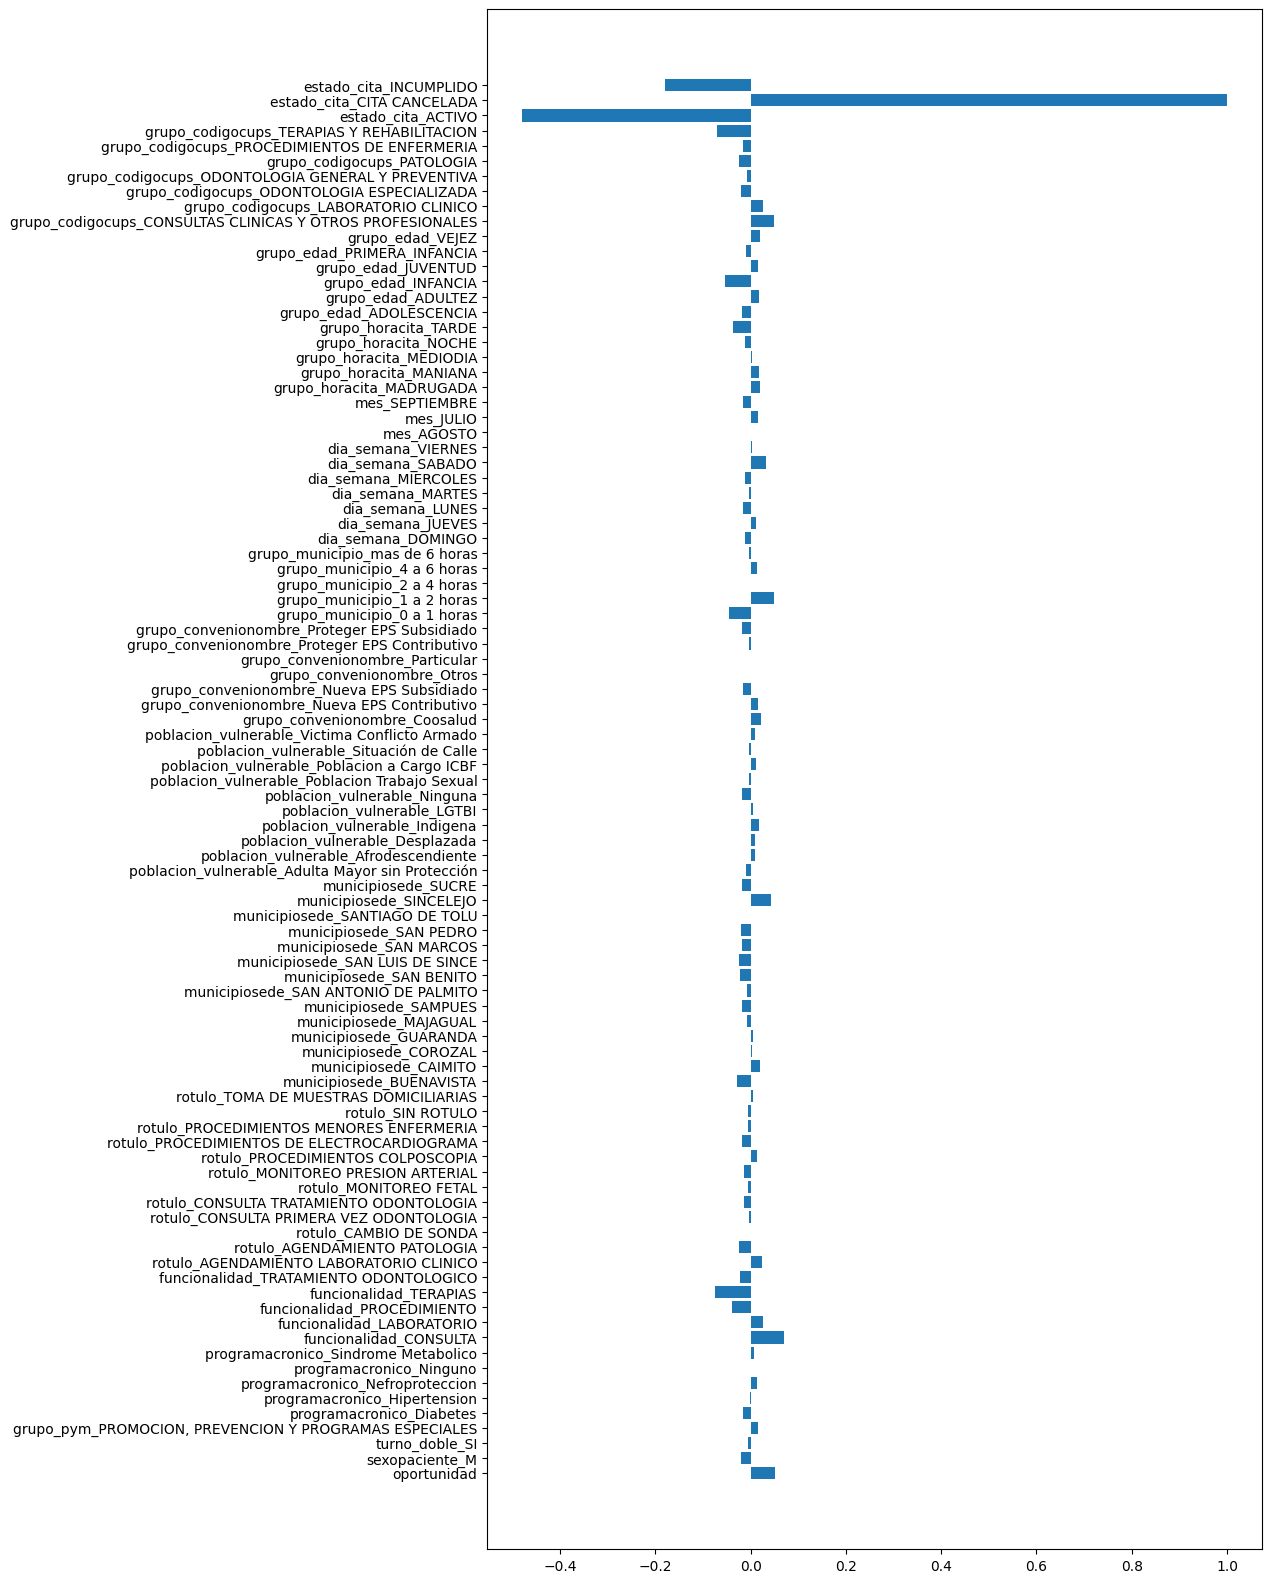

In [23]:
plt.figure(figsize=(10, 20))
plt.barh(y = data_sf.columns, width=cor_variable_interes_cancelada)

<BarContainer object of 93 artists>

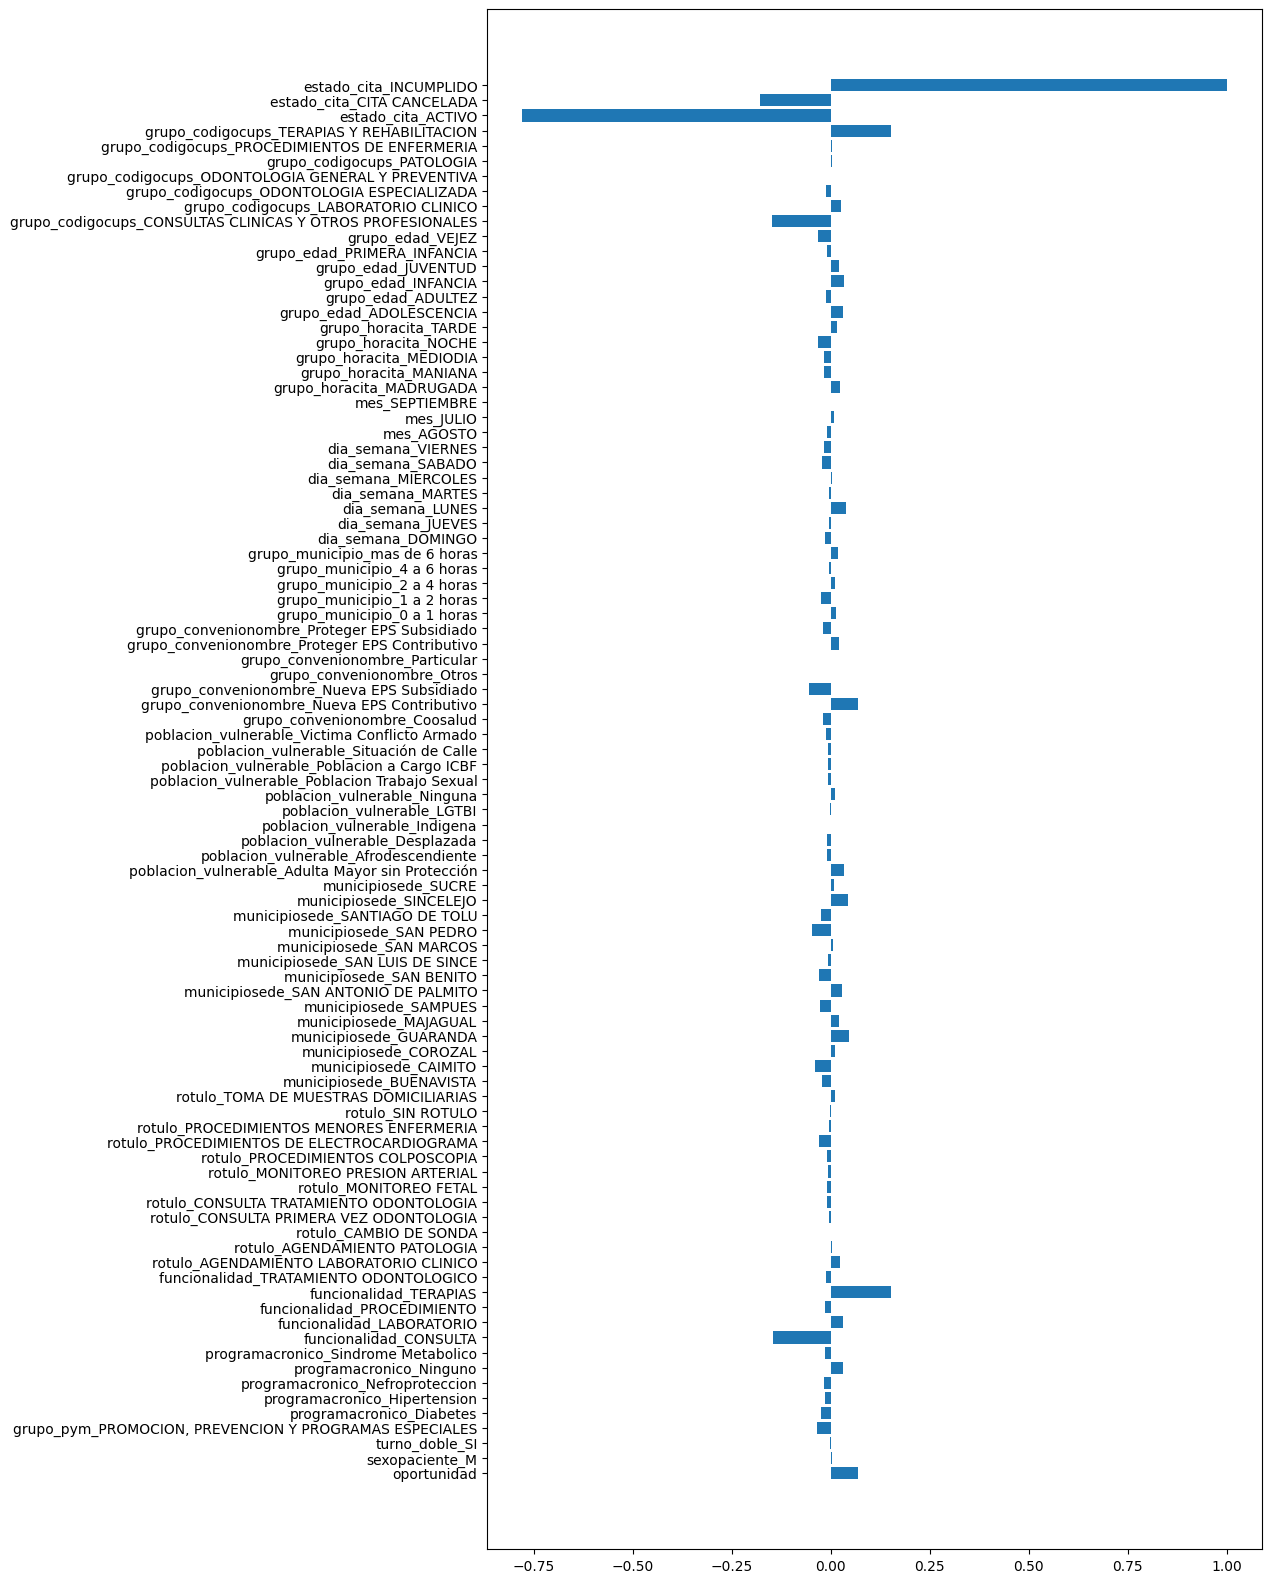

In [24]:
plt.figure(figsize=(10, 20))
plt.barh(y = data_sf.columns, width=cor_variable_interes_incumplida)

#### Interpretación y Evaluación de Relaciones Lineales: Cita Cancelada vs. Cita Incumplida

##### 1. Validación Lógica y Estructural de los Datos
* **Exclusión Mutua:** Las variables `estado_cita_ACTIVO`, `estado_cita_CITA CANCELADA` y `estado_cita_INCUMPLIDO` muestran correlaciones negativas fuertes entre sí (ej. Activo vs. Cancelada de $-0.48$ y Activo vs. Incumplido de $-0.78$). Esto valida que los estados son lógicamente excluyentes: una cita no puede estar activa ni registrarse simultáneamente en múltiples categorías de inasistencia.

##### 2. Factores Clave en Citas Canceladas (`estado_cita_CITA CANCELADA`)
* **Bajo impacto lineal individual:** La gran mayoría de variables demográficas y geográficas presentan coeficientes muy cercanos a cero, indicando que las cancelaciones anticipadas no responden a una simple relación lineal aislada.
* **Oportunidad (Tiempo de espera):** Muestra una leve correlación positiva, sugiriendo que a mayor tiempo de espera entre la solicitud y la fecha, marginalmente incrementa la probabilidad de que el paciente cancele.
* **Servicios de Terapias:** `funcionalidad_TERAPIAS` y `grupo_codigocups_TERAPIAS Y REHABILITACION` presentan una ligera correlación negativa, lo que indica que estos servicios tienden a cancelarse con menor frecuencia frente al promedio.

##### 3. Factores Clave en Citas Incumplidas (`estado_cita_INCUMPLIDO`)
* **Mayor sensibilidad en Terapias:** A diferencia de las cancelaciones, `grupo_codigocups_TERAPIAS Y REHABILITACION` y `funcionalidad_TERAPIAS` muestran una correlación positiva moderada ($\approx 0.15$), revelando que los servicios de terapias concentran una mayor tasa de inasistencia sin previo aviso (*no-show*).
* **Oportunidad:** Al igual que en las cancelaciones, un mayor tiempo de espera (`oportunidad`) contribuye ligeramente a elevar el riesgo de incumplimiento por olvido.
* **Consultas Generales:** `funcionalidad_CONSULTA` muestra una leve correlación negativa, sugiriendo un riesgo marginalmente menor de incumplimiento directo en consultas generales frente a otros procedimientos.

##### 4. Conclusión Metodológica General
Dado que las variables individuales presentan un poder predictivo lineal bajo o moderado (con excepciones puntuales en terapias y tiempo de oportunidad), se comprueba que tanto las cancelaciones como los incumplimientos responden a **patrones complejos y no lineales**. Esto justifica plenamente el uso de modelos de clasificación avanzados como árboles de decisión.

####Relaciones no lineales: SelectKBest
**Grado de dependencia no lineal entre las predictoras y la de interés estado_cita_CITA CANCELADA**

In [25]:
#Dependencia no lineal:  Si la relación es curva, escalonada,etc.
#Estima qué tan diferentes son las distribuciones, porque conocer X reduce la incertidumbre sobre Y.

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression, f_classif, mutual_info_classif, mutual_info_regression

X= data_sf.drop('estado_cita_CITA CANCELADA', axis=1)
Y= data_sf['estado_cita_CITA CANCELADA']

bestfeatures = mutual_info_classif(X, Y, random_state=42)
bestfeatures

array([5.79280741e-03, 2.00562778e-03, 8.34851778e-03, 1.11597084e-03,
       1.74865801e-03, 0.00000000e+00, 0.00000000e+00, 1.60291131e-03,
       5.36469411e-05, 4.26322333e-03, 2.04975840e-03, 0.00000000e+00,
       0.00000000e+00, 5.57508989e-04, 1.64171484e-03, 1.44749353e-03,
       7.09917846e-04, 0.00000000e+00, 1.19640319e-04, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.32866455e-03,
       2.86130393e-03, 0.00000000e+00, 0.00000000e+00, 5.78443787e-03,
       3.66138840e-03, 4.85784714e-03, 0.00000000e+00, 4.85839218e-03,
       0.00000000e+00, 0.00000000e+00, 2.65078370e-03, 1.20752601e-03,
       0.00000000e+00, 3.01491323e-05, 6.45340116e-04, 1.67725679e-04,
       9.10087522e-04, 2.07589589e-03, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 4.20812439e-03, 0.00000000e+00, 0.00000000e+00,
       6.89148116e-04, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       1.87735682e-03, 0.00000000e+00, 2.42299341e-03, 0.00000000e+00,
      

<BarContainer object of 92 artists>

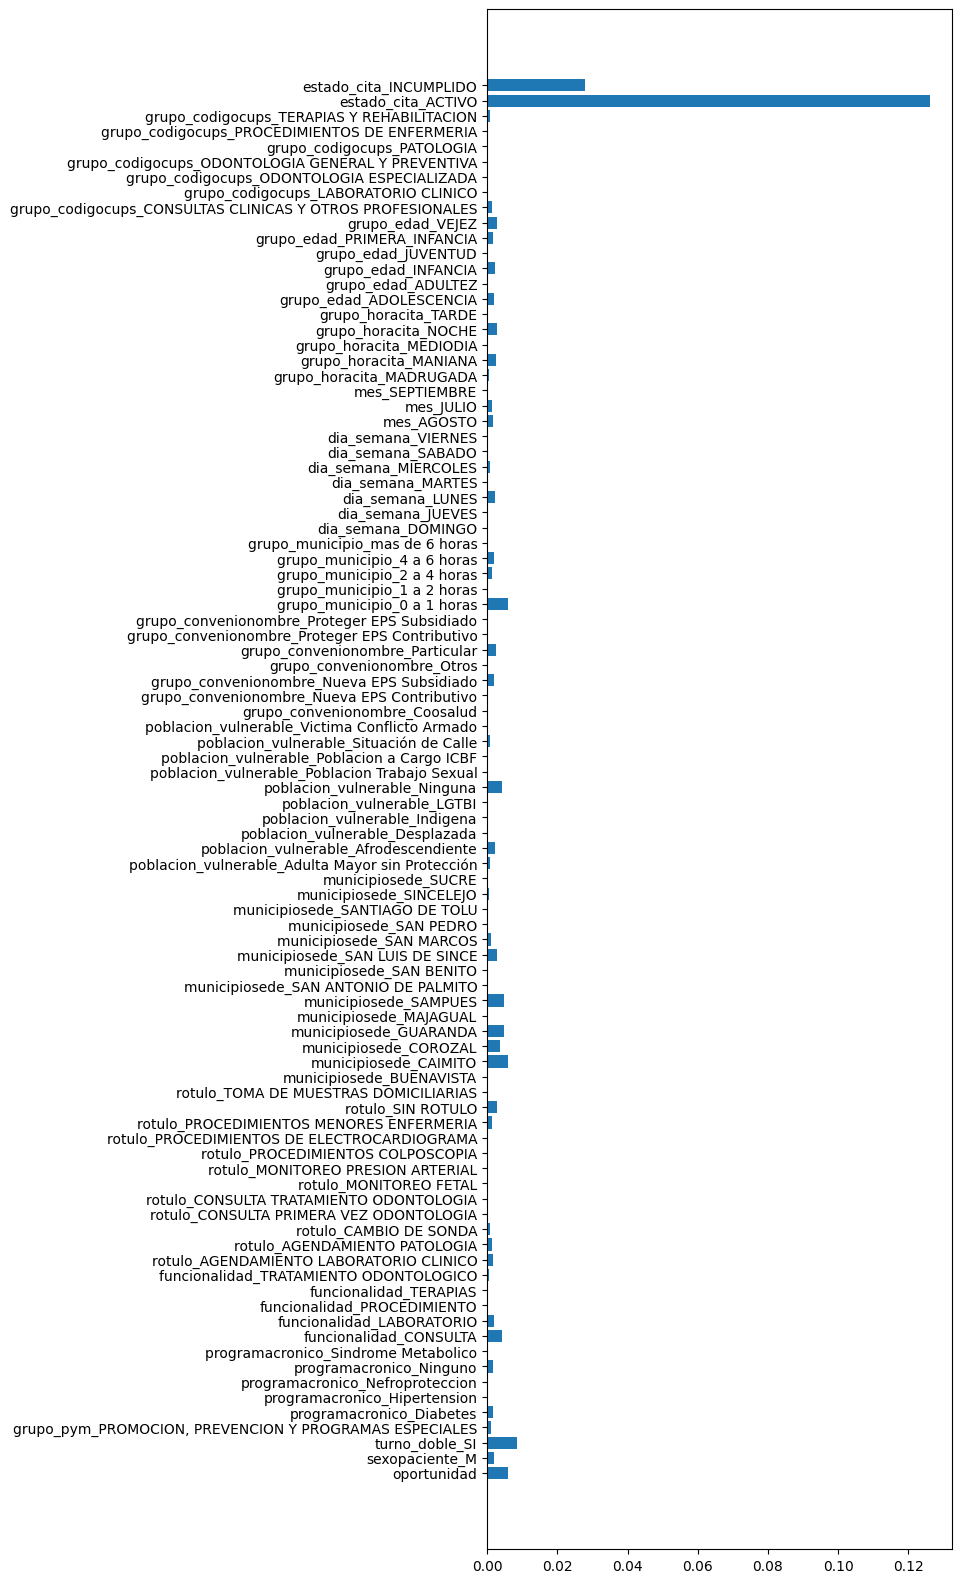

In [26]:
plt.figure(figsize=(6, 20))
plt.barh(y = X.columns, width=bestfeatures)

**Grado de dependencia no lineal entre las predictoras y la de interés estado_cita_INCUMPLIDO**

In [27]:
#Dependencia no lineal:  Si la relación es curva, escalonada,etc.
#Estima qué tan diferentes son las distribuciones, porque conocer X reduce la incertidumbre sobre Y.

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression, f_classif, mutual_info_classif, mutual_info_regression

X= data_sf.drop('estado_cita_INCUMPLIDO', axis=1)
Y= data_sf['estado_cita_INCUMPLIDO']

bestfeatures = mutual_info_classif(X, Y, random_state=42)
bestfeatures

array([0.01625309, 0.00087206, 0.        , 0.        , 0.00224069,
       0.        , 0.00139272, 0.        , 0.00042731, 0.0056975 ,
       0.00663901, 0.        , 0.01146207, 0.        , 0.        ,
       0.00275897, 0.        , 0.00084357, 0.        , 0.        ,
       0.00358968, 0.        , 0.        , 0.        , 0.00134126,
       0.00164495, 0.00108931, 0.        , 0.00519105, 0.009158  ,
       0.        , 0.        , 0.00212819, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.001952  , 0.00103085,
       0.        , 0.00470023, 0.00193202, 0.        , 0.        ,
       0.        , 0.        , 0.00224312, 0.        , 0.        ,
       0.00412494, 0.00255342, 0.00803486, 0.00086216, 0.00243062,
       0.        , 0.        , 0.001422  , 0.        , 0.00145855,
       0.        , 0.        , 0.00044422, 0.        , 0.00110535,
       0.        , 0.        , 0.00155951, 0.        , 0.        ,
       0.0006927 , 0.00448244, 0.        , 0.        , 0.     

<BarContainer object of 92 artists>

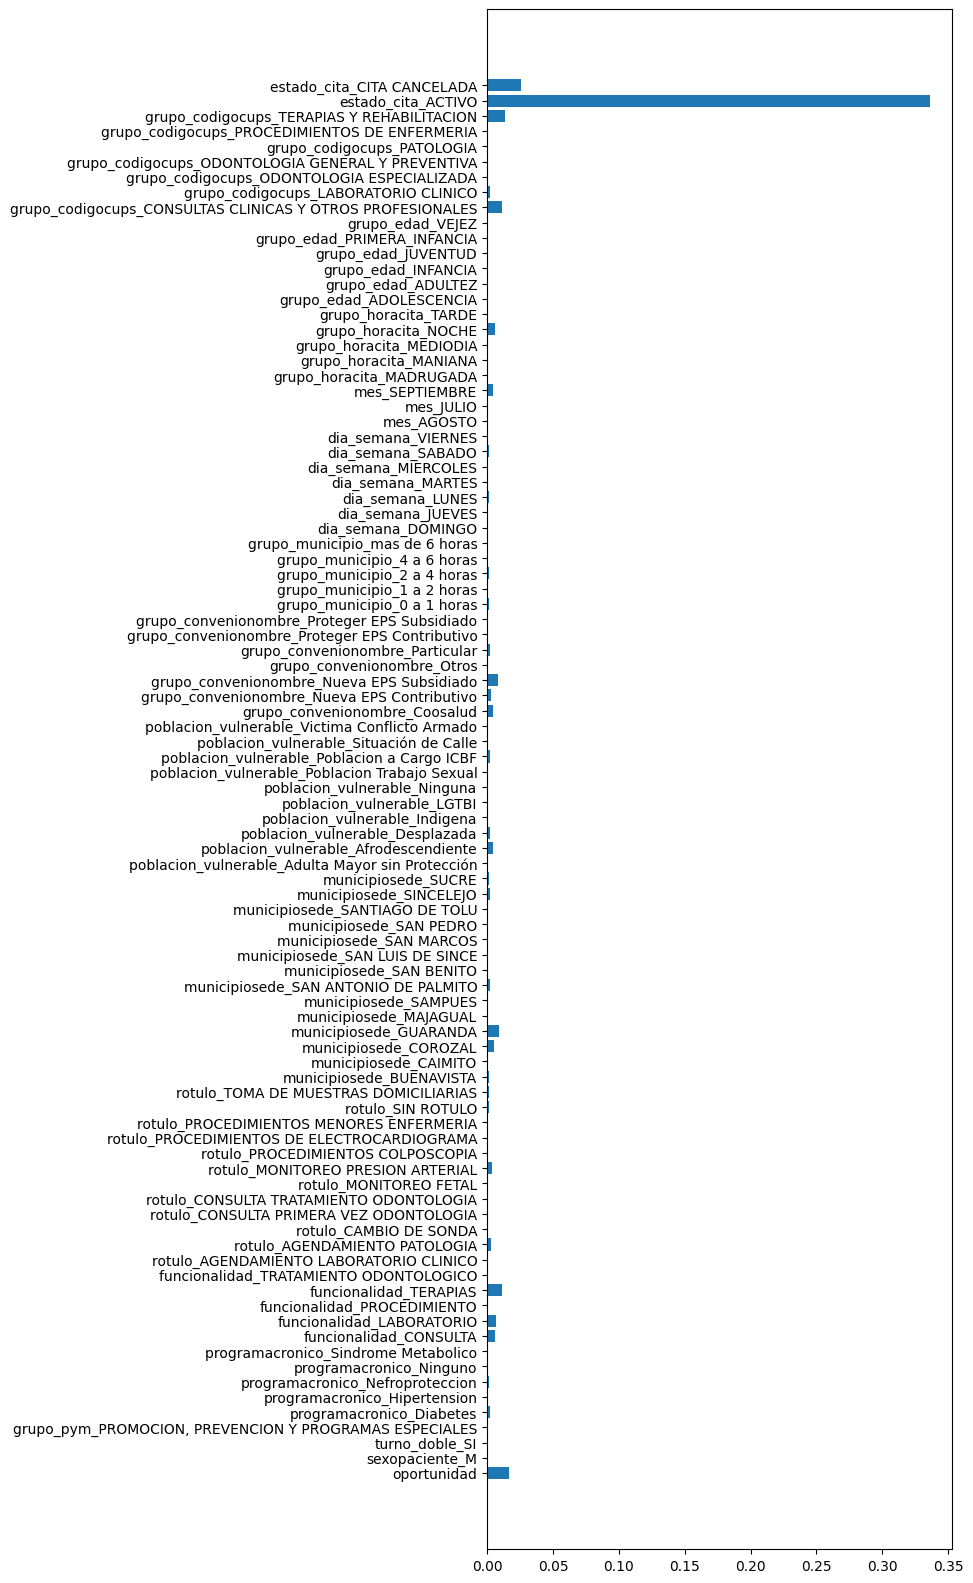

In [28]:
plt.figure(figsize=(6, 20))
plt.barh(y = X.columns, width=bestfeatures)

#### Análisis de Dependencia No Lineal (`mutual_info_classif`)

##### 1. Análisis: Citas Canceladas (`estado_cita_CITA CANCELADA`)
* **Validación de estados operativos:** Muestra una alta información mutua con `estado_cita_ACTIVO` y `estado_cita_INCUMPLIDO`, confirmando la exclusión mutua estructural de los registros.
* **Comportamiento univariado:** Excluyendo los estados operativos, la mayoría de las variables independientes presentan valores de información mutua muy cercanos a cero.
* **Factores relevantes:** La variable `oportunidad` (tiempo de espera) y `turno_doble_SI` presentan los mayores puntajes dentro de los atributos operativos, sugiriendo que la decisión de cancelar responde sutilmente a ventanas de tiempo prolongadas y dinámicas de programación anticipada.

##### 2. Análisis: Citas Incumplidas / No-Shows (`estado_cita_INCUMPLIDO`)
* **Sensibilidad operativa y de servicio:** Muestra una dependencia no lineal más marcada hacia la **`oportunidad`** y los servicios específicos de **terapias y rehabilitación** (`funcionalidad_TERAPIAS`, `grupo_codigocups_TERAPIAS Y REHABILITACION`), además de ciertos convenios.
* **Dinámica del incumplimiento:** A diferencia de las cancelaciones, la inasistencia sin previo aviso (*no-show*) se ve más influenciada por el paso del tiempo entre la asignación y la cita (riesgo de olvido) y el tipo de procedimiento solicitado.

##### 3. Conclusión de la Etapa de Selección de Factores
* **Aislamiento de fenómenos:** Evaluar ambas variables de forma independiente confirma que las cancelaciones anticipadas y los incumplimientos son dos comportamientos operativamente distintos que no deben mezclarse.
* **Justificación de modelos multivariados no lineales:** Dado que ningún atributo univariado (lineal o no lineal) explica por sí solo la totalidad del comportamiento, se confirma que el problema requiere **algoritmos multivariados complejos** (como árboles de decisión o modelos de ensamble) capaces de capturar interacciones simultáneas entre múltiples características.

####Árbol de Decisiones: selección de factores con RandomForest

In [29]:
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# 1. Muestreo estratificado de 15.000 registros
data_muestra_sl_tree, _ = train_test_split(
    data,
    train_size=15000,
    stratify=data[objetivo],
    random_state=42
)

print("Registros originales:", len(data))
print("Registros de la muestra:", len(data_muestra_sl_tree))
print("\nDistribución de la variable objetivo en la muestra:")
print(data_muestra_sl_tree[objetivo].value_counts(normalize=True) * 100)

Registros originales: 56411
Registros de la muestra: 15000

Distribución de la variable objetivo en la muestra:
estado_cita
ACTIVO            67.56
INCUMPLIDO        22.52
CITA CANCELADA     9.92
Name: proportion, dtype: float64


In [30]:
# 2. Separación de variables predictoras y objetivo
X = data_muestra_sl_tree.drop(columns=[objetivo])
Y = data_muestra_sl_tree[objetivo]

# Codificación de la variable objetivo (Y)
labelencoder = LabelEncoder()
Y_encoded = labelencoder.fit_transform(Y)

In [31]:
# 3. Configuración de Estrategias de Balanceo
# En este tipo de análisis es opcional, pero lo usamos para evitar/controlar sesgo de clases en el árbol)

# Estrategia 1: Reducir ACTIVO aproximadamente al 50 % de sus registros
def estrategia_undersampling(Y_train):
    cantidad_activos = (Y_train == 0).sum()
    return {0: int(cantidad_activos * 0.5)}

under = RandomUnderSampler(
    sampling_strategy=estrategia_undersampling,
    random_state=42
)

# Estrategia 2: Aumentar CITA CANCELADA un 100 %
def estrategia_balanceo(Y_train):
    cantidad_canceladas = (Y_train == 1).sum()
    return {1: cantidad_canceladas * 2}

# Se utiliza SMOTE estándar sobre los datos previamente codificados numéricamente
smote = SMOTE(
    sampling_strategy=estrategia_balanceo,
    k_neighbors=5,
    random_state=42
)

In [32]:
# 4. Transformador de Variables Predictoras
transformador = ColumnTransformer(
    transformers=[
        ('binarias', OrdinalEncoder(), predictoras_categoricas_2cat),
        ('multiclase', OneHotEncoder(handle_unknown='ignore', sparse_output=False), predictoras_categoricas_multicat)
    ],
    remainder='passthrough'
)

In [33]:
# 5. Construcción del Pipeline Híbrido Integral
# El orden garantiza que la transformación sea el primer paso, permitiendo a SMOTE trabajar
# directamente sobre una matriz numérica y aplicando el balanceo solo sobre el set de entrenamiento de cada fold.
pipeline_seleccion = ImbPipeline(steps=[
    ('transf', transformador),
    ('under', under),
    ('smote', smote),
    ('modelo', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced',
        max_depth=6  # Limitado para favorecer la interpretabilidad en el análisis descriptivo
    ))
])


In [34]:
# 6. Ajuste del Modelo con los Datos Completos de la Muestra
print("Entrenando el modelo para la selección de factores...")
pipeline_seleccion.fit(X, Y_encoded)

# Extraer el modelo entrenado y los nombres de las características transformadas
modelo_entrenado = pipeline_seleccion.named_steps['modelo']

# Obtener los nombres de las columnas después de aplicar el ColumnTransformer
# (Nota: OneHotEncoder genera múltiples columnas, por lo que recuperamos los nombres dinámicamente)
ohe = pipeline_seleccion.named_steps['transf'].named_transformers_['multiclase']
nombres_multiclase = list(ohe.get_feature_names_out(predictoras_categoricas_multicat))
nombres_binarias = list(predictoras_categoricas_2cat)

# Identificar las variables restantes (remainder='passthrough')
columnas_usadas = predictoras_categoricas_2cat + predictoras_categoricas_multicat
columnas_restantes = [col for col in X.columns if col not in columnas_usadas]
nombres_columnas_finales = nombres_binarias + nombres_multiclase + columnas_restantes

Entrenando el modelo para la selección de factores...


In [35]:
# 7. Selección y Análisis de Importancia de Factores
# Opción A: Usar SelectFromModel automáticamente
selector = SelectFromModel(modelo_entrenado, prefit=True)
selected_mask = selector.get_support()
variables_seleccionadas = np.array(nombres_columnas_finales)[selected_mask]

print("\n--- Variables Seleccionadas por el Modelo ---")
print(variables_seleccionadas)
print()
print()

# Opción B: Ver un ranking completo de importancia para tu tesis o informe descriptivo
importancias = modelo_entrenado.feature_importances_
df_importancias = pd.DataFrame({
    'Factor': nombres_columnas_finales,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print("\n--- Ranking de Importancia de Factores ---")
print(df_importancias.head(15))


--- Variables Seleccionadas por el Modelo ---
['sexopaciente' 'funcionalidad_CONSULTA' 'funcionalidad_TERAPIAS'
 'rotulo_PROCEDIMIENTOS COLPOSCOPIA' 'poblacion_vulnerable_Ninguna'
 'grupo_convenionombre_Nueva EPS Contributivo'
 'grupo_convenionombre_Nueva EPS Subsidiado' 'grupo_municipio_1 a 2 horas'
 'dia_semana_JUEVES' 'dia_semana_VIERNES' 'mes_AGOSTO' 'mes_JULIO'
 'grupo_edad_ADULTEZ' 'grupo_edad_VEJEZ' 'oportunidad']



--- Ranking de Importancia de Factores ---
                                         Factor  Importancia
86                                  oportunidad     0.320741
11                       funcionalidad_TERAPIAS     0.182998
78                             grupo_edad_VEJEZ     0.085115
8                        funcionalidad_CONSULTA     0.085046
66                                    mes_JULIO     0.037720
50    grupo_convenionombre_Nueva EPS Subsidiado     0.037709
59                            dia_semana_JUEVES     0.036599
54                  grupo_municipio_1 a 

#### Análisis de Importancia de Factores (Random Forest)

##### 1. Factor Crítico y Dominante
* **Oportunidad (32.07%):** El tiempo transcurrido entre la solicitud de la cita y su asignación/realización es, por amplio margen, el factor más determinante que explica el comportamiento del paciente (inasistencia o cancelación).

##### 2. Influencia del Tipo de Servicio y Especialidad
* **Funcionalidad (26.80% combinado):** Las variables de `funcionalidad_TERAPIAS` (~ 18.30%) y `funcionalidad_CONSULTA` (~ 8.50%) muestran un impacto elevado. La naturaleza del servicio condiciona fuertemente la adherencia del usuario a la cita.

##### 3. Segmentación Demográfica y Etaria
* **Grupo Etario (Vejez):** La categoría `grupo_edad_VEJEZ` (~ 8.51%) destaca significativamente por encima de otras edades o del sexo del paciente, evidenciando la necesidad de estrategias de gestión diferenciadas para la tercera edad.

##### 4. Factores Contextuales y Operativos
* **Estacionalidad y Agenda:** Variables temporales como `mes_JULIO` (~ 3.77%) y `dia_semana_JUEVES` (~ 3.66%) aportan un peso moderado, reflejando patrones de calendario en el comportamiento de asistencia.
* **Afiliación y Ubicación:** El tipo de convenio (`Nueva EPS Subsidiado`) y el desplazamiento geográfico (`1 a 2 horas`) actúan como barreras secundarias pero relevantes.

#### Conclusión General sobre la Selección de Factores

##### 1. Complementariedad Metodológica
* **Relaciones Lineales y No Lineales:** Los análisis univariados (correlación e información mutua) demostraron que ningún atributo aislado explica por sí solo el problema de manera contundente, confirmando que las cancelaciones e incumplimientos responden a dinámicas complejas y no lineales.
* **Modelo de Random Forest:** Logró capitalizar dicha complejidad multivariada, permitiendo jerarquizar los atributos mediante su importancia relativa en las divisiones del ensamble.

##### 2. Factores Determinantes Unificados
* **Oportunidad (Tiempo de Espera):** Emergió de forma consistente en los tres métodos como la variable operativa dominante, concentrando el mayor peso explicativo sobre el comportamiento del usuario.
* **Tipo de Servicio y Especialidad:** La funcionalidad del servicio (`TERAPIAS` y `CONSULTA`) se posicionó en todos los enfoques como un eje secundario pero altamente crítico que condiciona la adherencia o inasistencia.

# 3. Clustering
**Paola Andrea Duque Zuluaga**

**Muestra para clustering**

El clustering se realiza sobre una muestra estratificada de 15.000 citas, . La estratificación por `estado_cita` conserva la proporción original de citas activas, incumplidas y canceladas.

In [36]:
# Muestreo estratificado de 15.000 registros para clustering
# Se usa la semilla (random_state=42)
# para trabajar los modelos sobre exactamente las mismas citas
from sklearn.model_selection import train_test_split

data_muestra_cl, _ = train_test_split(
    data,
    train_size=15000,
    stratify=data[objetivo],
    random_state=42
)

# Copy de data set  para clustering
data_cl = data_muestra_cl.copy()

print("Registros originales:", len(data))
print("Registros de la muestra:", len(data_cl))

Registros originales: 56411
Registros de la muestra: 15000


In [37]:
# Verificamos que la muestra conserve la distribución del estado_cita
comparacion = pd.DataFrame({
    'original (%)': data[objetivo].value_counts(normalize=True) * 100,
    'muestra (%)': data_muestra_cl[objetivo].value_counts(normalize=True) * 100
}).round(2)
comparacion

,original (%),muestra (%)
estado_cita,,
ACTIVO,67.56,67.56
INCUMPLIDO,22.52,22.52
CITA CANCELADA,9.92,9.92


In [38]:
#En clustering no hay variable objetivo: todas las variables son descriptoras
data_cl.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15000 entries, 12525 to 7998
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   oportunidad           15000 non-null  int64   
 1   sexopaciente          15000 non-null  category
 2   programacronico       15000 non-null  category
 3   funcionalidad         15000 non-null  category
 4   rotulo                15000 non-null  category
 5   municipiosede         15000 non-null  category
 6   turno_doble           15000 non-null  category
 7   poblacion_vulnerable  15000 non-null  category
 8   grupo_convenionombre  15000 non-null  category
 9   grupo_municipio       15000 non-null  category
 10  dia_semana            15000 non-null  category
 11  mes                   15000 non-null  category
 12  grupo_horacita        15000 non-null  category
 13  grupo_edad            15000 non-null  category
 14  grupo_pym             15000 non-null  category
 15  grup

In [39]:
#Normalizacion de variables númericas (0 a 1)

from sklearn.preprocessing import MinMaxScaler


variables_a_normalizar=['oportunidad'] #variables numéricas

min_max_scaler = MinMaxScaler()

min_max_scaler.fit(data_cl[variables_a_normalizar]) #Ajuste de parámetro
data_cl[variables_a_normalizar]= min_max_scaler.transform(data_cl[variables_a_normalizar])
data_cl.head()

,oportunidad,sexopaciente,programacronico,funcionalidad,rotulo,municipiosede,turno_doble,poblacion_vulnerable,grupo_convenionombre,grupo_municipio,dia_semana,mes,grupo_horacita,grupo_edad,grupo_pym,grupo_codigocups,estado_cita
12525,0.220000,M,Ninguno,TERAPIAS,SIN ROTULO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MANIANA,VEJEZ,CITA MORBILIDAD,TERAPIAS Y REHABILITACION,ACTIVO
45133,0.006667,F,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,NO,Ninguna,Proteger EPS Subsidiado,0 a 1 horas,VIERNES,JULIO,TARDE,ADULTEZ,CITA MORBILIDAD,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO
35014,0.026667,F,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,NO,Ninguna,Nueva EPS Subsidiado,1 a 2 horas,MARTES,JULIO,MEDIODIA,ADULTEZ,CITA MORBILIDAD,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO
7131,0.006667,F,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,VIERNES,AGOSTO,MADRUGADA,ADULTEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,ACTIVO
25362,0.000000,F,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,NO,Ninguna,Nueva EPS Subsidiado,0 a 1 horas,MIERCOLES,AGOSTO,MANIANA,ADULTEZ,CITA MORBILIDAD,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO


In [40]:
# Se crean dummies para las variables de 2 categorías (se borra una)
data_cl = pd.get_dummies(data_cl, columns=['sexopaciente', 'turno_doble', 'grupo_pym'], drop_first=True, dtype=int)
data_cl.head()

,oportunidad,programacronico,funcionalidad,rotulo,municipiosede,poblacion_vulnerable,grupo_convenionombre,grupo_municipio,dia_semana,mes,grupo_horacita,grupo_edad,grupo_codigocups,estado_cita,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES"
12525,0.220000,Ninguno,TERAPIAS,SIN ROTULO,SINCELEJO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MANIANA,VEJEZ,TERAPIAS Y REHABILITACION,ACTIVO,1,0,0
45133,0.006667,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,Ninguna,Proteger EPS Subsidiado,0 a 1 horas,VIERNES,JULIO,TARDE,ADULTEZ,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,0,0,0
35014,0.026667,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,Ninguna,Nueva EPS Subsidiado,1 a 2 horas,MARTES,JULIO,MEDIODIA,ADULTEZ,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,0,0,0
7131,0.006667,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,VIERNES,AGOSTO,MADRUGADA,ADULTEZ,LABORATORIO CLINICO,ACTIVO,0,0,1
25362,0.000000,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,Ninguna,Nueva EPS Subsidiado,0 a 1 horas,MIERCOLES,AGOSTO,MANIANA,ADULTEZ,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,0,0,0


In [41]:
#Dummies variables con 2 o más categorías (no se borra ninguna)
data_cl = pd.get_dummies(data_cl, columns=['programacronico', 'funcionalidad', 'rotulo', 'municipiosede',
                                           'poblacion_vulnerable', 'grupo_convenionombre', 'grupo_municipio',
                                           'dia_semana', 'mes', 'grupo_horacita', 'grupo_edad',
                                           'grupo_codigocups', 'estado_cita'], drop_first=False, dtype=int) #No borrar dummy
data_cl.head()

,oportunidad,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",programacronico_Diabetes,programacronico_Hipertension,programacronico_Nefroproteccion,programacronico_Ninguno,programacronico_Sindrome Metabolico,funcionalidad_CONSULTA,...,grupo_codigocups_CONSULTAS CLINICAS Y OTROS PROFESIONALES,grupo_codigocups_LABORATORIO CLINICO,grupo_codigocups_ODONTOLOGIA ESPECIALIZADA,grupo_codigocups_ODONTOLOGIA GENERAL Y PREVENTIVA,grupo_codigocups_PATOLOGIA,grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,grupo_codigocups_TERAPIAS Y REHABILITACION,estado_cita_ACTIVO,estado_cita_CITA CANCELADA,estado_cita_INCUMPLIDO
12525,0.220000,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,1,0,0
45133,0.006667,0,0,0,0,0,0,1,0,1,...,1,0,0,0,0,0,0,1,0,0
35014,0.026667,0,0,0,0,0,0,1,0,1,...,1,0,0,0,0,0,0,1,0,0
7131,0.006667,0,0,1,0,0,0,1,0,0,...,0,1,0,0,0,0,0,1,0,0
25362,0.000000,0,0,0,0,0,0,1,0,1,...,1,0,0,0,0,0,0,1,0,0


In [42]:
#Revisamos el número de filas y columnas después de las dummies
data_cl.shape

(15000, 93)

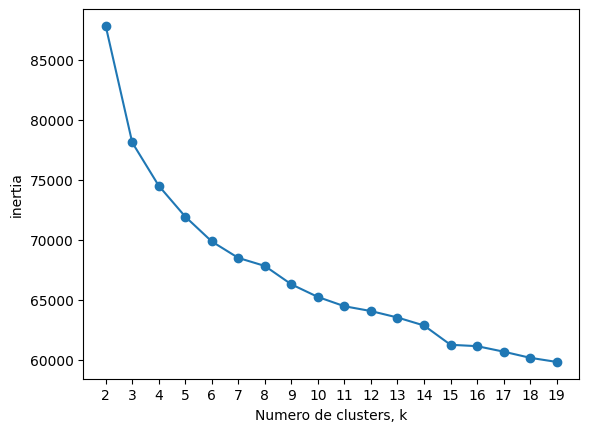

In [43]:
#Método del codo para encontrar la mejor cantidad de clusters: inertia
from sklearn.cluster import KMeans

ks = range(2, 20) # crear valores del 2 al 20
inertias = []

for k in ks:
    # Crear  modelo
    # random_state=7: semilla que fija el azar del punto de inicio del KMeans,
    # para que los grupos salgan siempre iguales cada vez que se corre el código
    model = KMeans(n_clusters=k, max_iter=300, random_state=7)
    model.fit(data_cl)
    inertias.append(model.inertia_)


# Graficar cantidad de clusters vs inertias
plt.plot(ks, inertias, '-o')
plt.xlabel('Numero de clusters, k')
plt.ylabel('inertia')
plt.xticks(ks)
plt.show()

En el gráfico se observa que:

Entre k = 2 y k = 3 se da la caída más pronunciada de toda la curva.
Entre k = 3 y k = 4 la inercia sigue bajando, aunque con menos fuerza; esta reducción es mayor que cualquiera de las que se dan después.
A partir de k = 4 la curva se vuelve más plana y cada cluster adicional aporta una mejora pequeña.

Visualmente, el codo se forma en la zona entre k = 3 y k = 4: desde ese punto, agregar más clusters no reduce la inercia de forma importante.

Se observan además algunas irregularidades en la curva: entre k = 7 y k = 8 la inercia casi no baja, y entre k = 14 y k = 15 baja un poco más que en los valores cercanos.a una solución menos óptima. No afecta la lectura general de la curva.

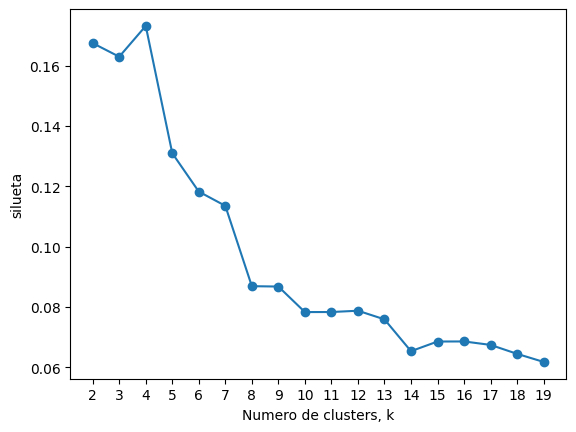

In [44]:
#Método de la rodilla: silueta
from sklearn import metrics

ks = range(2, 20) # crear valores del 2 al 20
siluetas = []

for k in ks:
    # Crear  modelo (se entrena con las 15.000 citas de la muestra)
    model = KMeans(n_clusters=k, max_iter=300, random_state=7)
    model.fit(data_cl)
    # Con la muestra de 15.000 la silueta se calcula con todos los registros
    sil=metrics.silhouette_score(data_cl, model.labels_)
    siluetas.append(sil)

# Graficar cantidad de clusters vs silueta
plt.plot(ks, siluetas, '-o')
plt.xlabel('Numero de clusters, k')
plt.ylabel('silueta')
plt.xticks(ks)
plt.show()

En el gráfico se observa que:

El valor más alto de toda la curva se presenta en k = 4, seguido de k = 2 y k = 3, que tienen valores muy cercanos entre sí. Entre k = 4 y k = 5 se da la caída más pronunciada de toda la curva. La silueta sigue bajando hasta k = 7, y entre k = 7 y k = 8 presenta otra caída importante. A partir de k = 8 se mantiene baja, con pequeñas variaciones; el valor más bajo se observa en k = 19.

**Ningún valor de k alcanza 0,5, umbral a partir del cual se considera que los grupos están bien separados**

Los valores de silueta se encuentran por debajo de 0,2, lo que indica que los clusters comparten varias características entre sí. Esto se relaciona con la naturaleza de la base.

Aun así, los clusters pueden aportar información útil para describir la base, lo cual se revisará al analizar el perfil de cada cluster.


In [45]:
#Tabla con los valores del codo y la silueta para cada k
tabla_k = pd.DataFrame({'k': list(ks), 'inercia': inertias, 'silueta': siluetas})
tabla_k.round(5)

,k,inercia,silueta
0,2,87810.69972,0.16745
1,3,78097.96438,0.16295
2,4,74492.51547,0.17316
3,5,71919.02221,0.13095
4,6,69848.75576,0.11822
5,7,68480.97170,0.11350
6,8,67811.14672,0.08685
7,9,66278.59979,0.08673
8,10,65227.02952,0.07827
9,11,64454.88188,0.07828


**Selección del número de clusters**

Al comparar el método del codo y el coeficiente de silueta:

El método del codo muestra el cambio de pendiente entre k = 3 y k = 4: desde ese punto, agregar más clusters reduce poco la inercia.
El coeficiente de silueta presenta su valor más alto en k = 4 (0,173).

Ambos criterios coinciden en k = 4. Aunque k = 3 tiene una silueta similar, con 3 clusters las citas de procedimientos quedaban mezcladas con las consultas; con 4 clusters forman un grupo propio y los perfiles son más claros.

Por lo tanto, se seleccionaron 4 clusters.

In [46]:
#Creación de modelo de clustering con Kmeans
from sklearn.cluster import KMeans
k=4
model = KMeans(n_clusters=k, max_iter=300, random_state=7)
model.fit(data_cl) #muestra estratificada de 15.000 citas

KMeans(n_clusters=4, random_state=7)

##3.2 Evaluacion del Modelo (*Clustering* )


In [47]:
from sklearn import metrics

#Inertia: se require valor pequeño
print('Inercia o cohesión:', model.inertia_)

#Silueta: se requiere que sea positivo, ideal 0.5-1.0
sil=metrics.silhouette_score(data_cl, model.labels_)
print('Silueta:',sil)

Inercia o cohesión: 74492.51547179605
Silueta: 0.17316215551349365


El modelo final con 4 clusters obtuvo una inercia de 74.492,5 y una silueta de 0,173.

La silueta es positiva, lo que indica que los registros están, en general, más cerca de su propio cluster que de los demás. Sin embargo, está lejos del rango ideal (0,5 a 1,0), lo que muestra que los grupos comparten varias características entre sí. Aun así, el modelo permite identificar perfiles.

## 3.3 Perfilamiento

In [48]:
#Centroides almacenados dentro del modelo
model.cluster_centers_

array([[ 9.79106003e-02,  3.14176245e-01, -6.01732206e-18,
         2.65900383e-01,  2.29885057e-02,  6.20689655e-02,
         2.14559387e-02,  8.92720307e-01,  7.66283525e-04,
         7.66283525e-04, -4.96824804e-15,  9.52490421e-01,
        -4.66293670e-15,  4.67432950e-02, -3.27515792e-15,
         5.82375479e-02,  0.00000000e+00, -1.57209315e-18,
         4.75095785e-02,  3.21839080e-02,  1.91570881e-02,
         5.21072797e-02,  6.16091954e-01,  7.81609195e-02,
         9.65517241e-02,  1.27935856e-17,  2.52873563e-02,
         4.98084291e-02,  8.42911877e-03,  1.27935856e-17,
         1.45593870e-02,  3.14176245e-02,  1.30268199e-02,
         9.96168582e-03,  2.84494650e-16,  3.14176245e-02,
         2.06896552e-02, -6.21031004e-16,  7.95402299e-01,
        -4.29344060e-17, -8.45677695e-18,  5.36398467e-03,
         1.53256705e-03,  1.19262239e-17,  7.66283525e-04,
         9.86973180e-01, -3.14418630e-18,  7.66283525e-04,
         7.66283525e-04,  3.83141762e-03,  1.30268199e-0

In [49]:
#Centroides de los cluster se convierten  en un dataframe de pandas
centroides=pd.DataFrame(model.cluster_centers_, columns=data_cl.columns.values)
centroides.round(1)

,oportunidad,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",programacronico_Diabetes,programacronico_Hipertension,programacronico_Nefroproteccion,programacronico_Ninguno,programacronico_Sindrome Metabolico,funcionalidad_CONSULTA,...,grupo_codigocups_CONSULTAS CLINICAS Y OTROS PROFESIONALES,grupo_codigocups_LABORATORIO CLINICO,grupo_codigocups_ODONTOLOGIA ESPECIALIZADA,grupo_codigocups_ODONTOLOGIA GENERAL Y PREVENTIVA,grupo_codigocups_PATOLOGIA,grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,grupo_codigocups_TERAPIAS Y REHABILITACION,estado_cita_ACTIVO,estado_cita_CITA CANCELADA,estado_cita_INCUMPLIDO
0,0.1,0.3,-0.0,0.3,0.0,0.1,0.0,0.9,0.0,0.0,...,0.8,0.1,0.0,-0.0,0.1,0.1,0.0,0.8,0.1,0.2
1,0.0,0.3,0.0,0.1,0.0,0.1,0.0,0.9,0.0,1.0,...,1.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.7,0.1,0.2
2,0.1,0.4,0.0,-0.0,0.0,0.0,0.0,0.9,0.0,-0.0,...,0.0,0.0,0.0,-0.0,0.0,-0.0,1.0,0.6,0.1,0.3
3,0.2,0.4,0.0,0.5,0.0,0.0,0.0,0.9,0.0,0.0,...,-0.0,1.0,0.0,-0.0,0.0,-0.0,-0.0,0.6,0.1,0.3


In [50]:
# Se realiza una des-normalización centroides
centroides[variables_a_normalizar]=min_max_scaler.inverse_transform(centroides[variables_a_normalizar])
centroides.round(1)

,oportunidad,sexopaciente_M,turno_doble_SI,"grupo_pym_PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",programacronico_Diabetes,programacronico_Hipertension,programacronico_Nefroproteccion,programacronico_Ninguno,programacronico_Sindrome Metabolico,funcionalidad_CONSULTA,...,grupo_codigocups_CONSULTAS CLINICAS Y OTROS PROFESIONALES,grupo_codigocups_LABORATORIO CLINICO,grupo_codigocups_ODONTOLOGIA ESPECIALIZADA,grupo_codigocups_ODONTOLOGIA GENERAL Y PREVENTIVA,grupo_codigocups_PATOLOGIA,grupo_codigocups_PROCEDIMIENTOS DE ENFERMERIA,grupo_codigocups_TERAPIAS Y REHABILITACION,estado_cita_ACTIVO,estado_cita_CITA CANCELADA,estado_cita_INCUMPLIDO
0,14.7,0.3,-0.0,0.3,0.0,0.1,0.0,0.9,0.0,0.0,...,0.8,0.1,0.0,-0.0,0.1,0.1,0.0,0.8,0.1,0.2
1,6.3,0.3,0.0,0.1,0.0,0.1,0.0,0.9,0.0,1.0,...,1.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.7,0.1,0.2
2,16.3,0.4,0.0,-0.0,0.0,0.0,0.0,0.9,0.0,-0.0,...,0.0,0.0,0.0,-0.0,0.0,-0.0,1.0,0.6,0.1,0.3
3,35.2,0.4,0.0,0.5,0.0,0.0,0.0,0.9,0.0,0.0,...,-0.0,1.0,0.0,-0.0,0.0,-0.0,-0.0,0.6,0.1,0.3


##3.4 Descripcion de Perfiles

In [51]:
#Copia de la muestra de clustering con valores reales (sin normalizar ni dummies)
#Se usa data_muestra_cl y no data, para que las filas coincidan con las etiquetas del modelo
df = data_muestra_cl.copy()

#Se adiciona el cluster asignado a cada registro
df['cluster']=model.labels_
df.head()

,oportunidad,sexopaciente,programacronico,funcionalidad,rotulo,municipiosede,turno_doble,poblacion_vulnerable,grupo_convenionombre,grupo_municipio,dia_semana,mes,grupo_horacita,grupo_edad,grupo_pym,grupo_codigocups,estado_cita,cluster
12525,33,M,Ninguno,TERAPIAS,SIN ROTULO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,MIERCOLES,JULIO,MANIANA,VEJEZ,CITA MORBILIDAD,TERAPIAS Y REHABILITACION,ACTIVO,2
45133,1,F,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,NO,Ninguna,Proteger EPS Subsidiado,0 a 1 horas,VIERNES,JULIO,TARDE,ADULTEZ,CITA MORBILIDAD,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,1
35014,4,F,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,NO,Ninguna,Nueva EPS Subsidiado,1 a 2 horas,MARTES,JULIO,MEDIODIA,ADULTEZ,CITA MORBILIDAD,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,1
7131,1,F,Ninguno,LABORATORIO,AGENDAMIENTO LABORATORIO CLINICO,SINCELEJO,NO,Ninguna,Nueva EPS Contributivo,0 a 1 horas,VIERNES,AGOSTO,MADRUGADA,ADULTEZ,"PROMOCION, PREVENCION Y PROGRAMAS ESPECIALES",LABORATORIO CLINICO,ACTIVO,3
25362,0,F,Ninguno,CONSULTA,SIN ROTULO,SINCELEJO,NO,Ninguna,Nueva EPS Subsidiado,0 a 1 horas,MIERCOLES,AGOSTO,MANIANA,ADULTEZ,CITA MORBILIDAD,CONSULTAS CLINICAS Y OTROS PROFESIONALES,ACTIVO,1


In [52]:
# Exportar la muestra con su cluster a CSV
df.to_csv("muestra_clusters.csv", index=False, encoding="utf-8-sig")

<Axes: ylabel='count'>

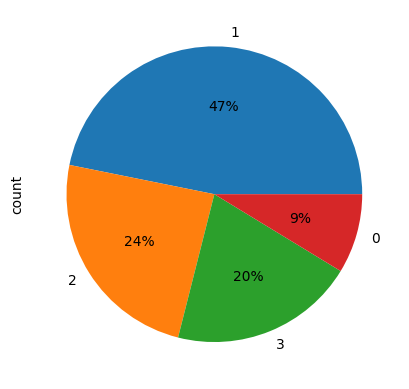

In [53]:
#Cantidad de datos en cada cluster
df["cluster"].value_counts().plot(kind='pie',autopct='%.0f%%')

**Cluster 0** – Procedimientos diagnósticos (8,7 %)
Es un grupo pequeño de citas para procedimientos, sobre todo electrocardiogramas. Se agendan principalmente en la mañana y los pacientes suelen ser adultos mayores, tanto del régimen subsidiado como del contributivo. La mayoría de estas citas se asigna en pocos días, aunque algunas tienen esperas largas. Es el grupo que mejor cumple: el 76 % de las citas queda activa y muy pocas se cancelan.
Estrategia: mantener la forma actual de agendamiento y revisar los casos con esperas largas para que no terminen en inasistencia.

**Cluster 1** – Consultas médicas de población subsidiada (46,8 %)
Es el grupo más grande. Reúne las consultas médicas y con otros profesionales, en la mañana o en la tarde, de pacientes adultos y niños pequeños, en su mayoría del régimen subsidiado (77 %). Es el grupo con más pacientes atendidos fuera de Sincelejo. Tiene la espera más corta, de unos 6 días, y pocos incumplimientos, pero es de los que más cancelan.
Estrategia: confirmar la cita uno o dos días antes por mensaje o llamada, y facilitar la reprogramación para que los cupos cancelados se puedan reasignar rápido.

**Cluster 2** – Terapias y rehabilitación en la tarde (24,2 %)
Citas de terapias y rehabilitación, la mayoría en la tarde. Hay pacientes de todas las edades, desde niños hasta adultos mayores, y de ambos regímenes. Es el grupo con más presencia de hombres. Es el que más incumple: el 34 % de las citas no se cumple, el doble que en las consultas.
Estrategia: es el grupo prioritario. Conviene enviar recordatorios antes de cada sesión, ofrecer horarios más flexibles y hacer seguimiento a quienes faltan, porque las terapias necesitan continuidad para funcionar.

**Cluster 3** – Laboratorio clínico de madrugada (20,2 %)
Citas de laboratorio clínico, casi todas de madrugada (78 %), de adultos mayores del régimen contributivo y atendidos en Sincelejo. Casi la mitad corresponde a programas de promoción y prevención. Es el grupo con la espera más larga: en promedio, 35 días. Su incumplimiento es intermedio, de una de cada cuatro citas (25 %).
Estrategia: reducir los tiempos de espera, recordar la cita y las indicaciones previas (como el ayuno) el día anterior, y evaluar ampliar cupos o la toma de muestras a domicilio para adultos mayores.

**Conclusión**:

Los clusters se diferencian principalmente por el tipo de servicio: procedimientos, consultas, terapias y laboratorio. Cada uno tiene un comportamiento distinto frente a la asistencia. Las terapias y el laboratorio son los grupos con más incumplimiento (34 % y 25 %) y también con las esperas más largas, lo que sugiere que el tiempo de espera influye en que el paciente asista. Estos perfiles complementan el modelo de clasificación, porque ayudan a entender qué tipo de citas tienen más riesgo y a diseñar estrategias de agendamiento para cada grupo.


data_muestra_cl: muestra estratificada de 15.000 citas

data_cl: la muestra normalizada y con dummies, para entrenar el KMeans.

df: la muestra con valores reales más el cluster, para describir los perfiles.

# 4. Modelo de clasificación predictiva
**Katerin Giraldo Betancur**

In [54]:
# Muestreo estratificado de 15.000 registros
from sklearn.model_selection import train_test_split

data_muestra, _ = train_test_split(
    data,
    train_size=15000,
    stratify=data[objetivo],
    random_state=42
)

# Verificar tamaño y distribución de la muestra
print("Registros originales:", len(data))
print("Registros de la muestra:", len(data_muestra))

print("\nDistribución de la variable objetivo:")
print(data_muestra[objetivo].value_counts(normalize=True) * 100)

Registros originales: 56411
Registros de la muestra: 15000

Distribución de la variable objetivo:
estado_cita
ACTIVO            67.56
INCUMPLIDO        22.52
CITA CANCELADA     9.92
Name: proportion, dtype: float64


In [55]:
# Separación de variables predictoras y objetivo
# No se realiza sobre el dataframe directo, porque el balanceo necesita las variables categóricas
X = data_muestra.drop(columns=[objetivo])
Y = data_muestra[objetivo]


## Balanceo
Debido al desbalanceo de la variable objetivo, se aplica una estrategia de balanceo combinado: undersampling para reducir en un 50 % los registros de ACTIVO y SMOTENC para aumentar en un 100 % los registros de CITA CANCELADA conservando la cantidad original de INCUMPLIDO.

El balanceo se aplica únicamente a los datos de entrenamiento de cada partición de la validación cruzada, evitando fuga de información.

In [56]:
# LabelEncoder para la variable objetivo
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

In [57]:
# Configuración de StratifiedKFold
from sklearn.model_selection import StratifiedKFold

# Configuración de validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

In [58]:
# Variables categóricas para SMOTENC
columnas_categoricas = predictoras_categoricas_2cat + predictoras_categoricas_multicat

In [59]:
from imblearn.under_sampling import RandomUnderSampler

# Estrategia balanceo 1: Reducir ACTIVO aproximadamente al 50 % de sus registros
def estrategia_undersampling(Y_train):
    cantidad_activos = (Y_train == 0).sum()

    return {0: int(cantidad_activos * 0.5)}

under = RandomUnderSampler(
    sampling_strategy=estrategia_undersampling,
    random_state=42
)

In [60]:
from imblearn.over_sampling import SMOTENC


# Estrategia de balanceo 2: aumentar CITA CANCELADA un 100 %
def estrategia_balanceo(Y_train):
    cantidad_canceladas = (Y_train == 1).sum()
    return {1: cantidad_canceladas * 2}

# Configuración de SMOTENC
smote = SMOTENC(
    categorical_features=columnas_categoricas,
    sampling_strategy=estrategia_balanceo,
    k_neighbors=5,
    random_state=42
)


In [61]:
# Configuración para la transformación de variables predictoras
# La transformación se aplica después de SMOTENC y se integra al proceso de entrenamiento, ya que se realizará balanceo sobre los datos de entrenamiento

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

# Configuración de transformación de variables predictoras
transformador = ColumnTransformer(
    transformers=[
        ('binarias', OrdinalEncoder(),
         predictoras_categoricas_2cat),

        ('multiclase', OneHotEncoder(handle_unknown='ignore'),
         predictoras_categoricas_multicat)
    ],
    remainder='passthrough'
)

In [62]:
from sklearn.preprocessing import MinMaxScaler

# Transformaciones para modelos que requieren normalización
transformador_normalizado = ColumnTransformer(
    transformers=[
        ('categoricas',
         OneHotEncoder(drop='if_binary', handle_unknown='ignore'),
         columnas_categoricas),

        ('numericas',
         MinMaxScaler(),
         predictoras_numericas)
    ]
)

In [63]:
# Configuración de métricas de evaluación
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

## TREE

In [64]:
# Configuración del modelo Árbol de Decisión
from sklearn import tree

modelTree = tree.DecisionTreeClassifier(
    criterion='gini',
    min_samples_leaf=15,
    max_depth=10,
    random_state=42
)

from imblearn.pipeline import Pipeline

# Pipeline, ejecuta en el orden que aparece, 1. undersampling 2. balanceo, 3. transformo, 4. modelo
modeloTree = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador),
    ('clasificador', modelTree)
])

# Validación cruzada del Árbol de Decisión
from sklearn.model_selection import cross_validate

scoresTree = cross_validate(modeloTree, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

# Convertir resultados en DataFrame
scoresTree = pd.DataFrame(scoresTree)

scoresTree

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,1.957863,0.023797,0.559333,0.566963,0.459503,0.473338,0.501261,0.519324,0.462433,0.475570
1,1.381429,0.023209,0.520667,0.567481,0.424951,0.472937,0.447921,0.512416,0.417139,0.469314
2,1.378118,0.022542,0.524000,0.551926,0.438408,0.463733,0.477842,0.504882,0.433890,0.459557
3,1.471740,0.025675,0.565333,0.582815,0.438372,0.465431,0.455248,0.495894,0.439336,0.470781
4,1.388511,0.022631,0.560667,0.612889,0.412277,0.480969,0.420404,0.503723,0.413727,0.488286
5,1.398012,0.023016,0.522000,0.566593,0.412015,0.463656,0.433756,0.502282,0.410417,0.466097
6,1.373132,0.023206,0.522000,0.570519,0.417409,0.477269,0.440541,0.518037,0.410981,0.473257
7,2.108114,0.035122,0.551333,0.609852,0.402128,0.477658,0.410223,0.498273,0.400823,0.482999
8,2.027137,0.023465,0.524667,0.569778,0.422211,0.475963,0.447518,0.517142,0.414335,0.473001
9,3.197049,0.069226,0.566000,0.588222,0.436910,0.471940,0.450533,0.506944,0.436304,0.477650


In [65]:
# Promedios para evaluar overfitting comparando medidas de train y test
scoresTree.mean()

,0
fit_time,1.768111
score_time,0.029189
test_accuracy,0.541600
train_accuracy,0.578704
test_precision,0.426419
train_precision,0.472289
test_recall,0.448525
train_recall,0.507892
test_f1,0.423939
train_f1,0.473651


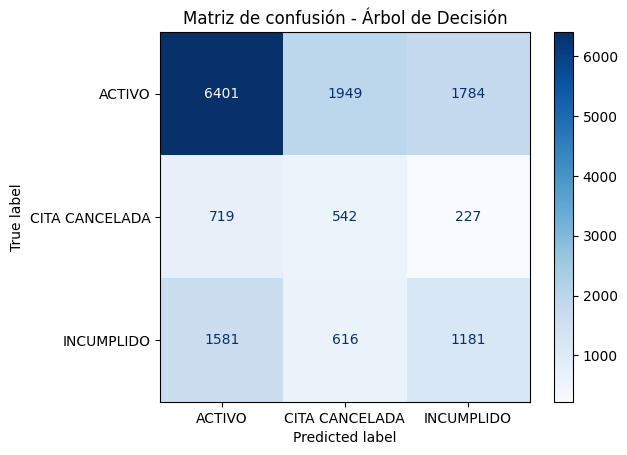

In [66]:
# Predicciones del Árbol de Decisión mediante validación cruzada
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Y_pred_Tree = cross_val_predict(modeloTree, X, Y, cv=cv)

# Matriz de confusión
matriz_Tree = confusion_matrix(Y, Y_pred_Tree)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_Tree, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Árbol de Decisión')
plt.show()

In [67]:
# DataFrame para comparar los resultados de validación cruzada
comparacion_CV = pd.DataFrame()
comparacion_CV['Tree'] = scoresTree['test_f1']
comparacion_CV

,Tree
0,0.462433
1,0.417139
2,0.433890
3,0.439336
4,0.413727
5,0.410417
6,0.410981
7,0.400823
8,0.414335
9,0.436304


## RANDOM FOREST

In [68]:
# Configuración del modelo Random Forest
from sklearn.ensemble import RandomForestClassifier

modelRF = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_depth=10, random_state=42)

# Pipeline para Random Forest con balanceo combinado
modeloRF = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador),
    ('clasificador', modelRF)
])

# Validación cruzada del Random Forest
scoresRF = cross_validate(modeloRF, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

# Convertir resultados en DataFrame
scoresRF = pd.DataFrame(scoresRF)

scoresRF

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,2.784931,0.054063,0.626000,0.644370,0.466383,0.494419,0.460002,0.488234,0.462782,0.491023
1,2.827619,0.051761,0.638667,0.657630,0.472185,0.500168,0.444814,0.468066,0.451154,0.478304
2,2.900874,0.071685,0.640667,0.652370,0.494112,0.499264,0.463493,0.479118,0.474599,0.487273
3,3.833459,0.050991,0.638000,0.653259,0.470590,0.499431,0.446035,0.479938,0.454708,0.487922
4,2.817448,0.047841,0.616667,0.645926,0.422340,0.495348,0.417175,0.479243,0.417695,0.485912
5,2.844241,0.046979,0.602000,0.645185,0.430870,0.494251,0.426261,0.486514,0.428118,0.489951
6,2.923150,0.070273,0.590000,0.639778,0.421277,0.490528,0.420528,0.485478,0.420885,0.487874
7,3.814002,0.049173,0.596667,0.654148,0.417535,0.506257,0.406202,0.487525,0.409995,0.494907
8,2.881226,0.047150,0.612667,0.653111,0.444820,0.503473,0.431273,0.482816,0.436565,0.491252
9,2.896600,0.048059,0.621333,0.647630,0.448546,0.499427,0.439216,0.487946,0.443130,0.493084


In [69]:
# Promedios para evaluar overfitting comparando medidas de train y test
scoresRF.mean()

,0
fit_time,3.052355
score_time,0.053798
test_accuracy,0.618267
train_accuracy,0.649341
test_precision,0.448866
train_precision,0.498257
test_recall,0.435500
train_recall,0.482488
test_f1,0.439963
train_f1,0.488750


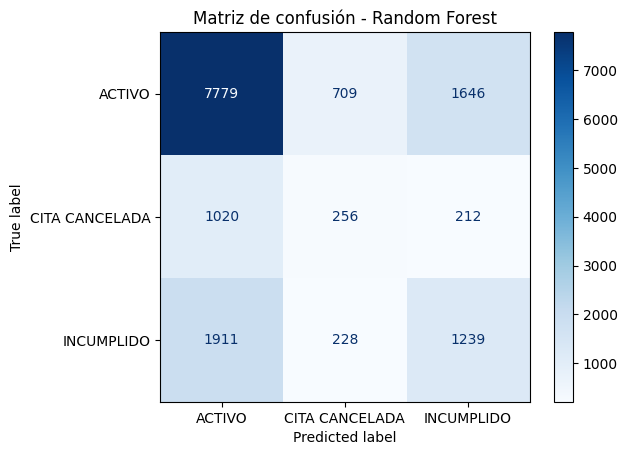

In [70]:
# Predicciones de Random Forest mediante validación cruzada
Y_pred_RF = cross_val_predict(modeloRF, X, Y, cv=cv)

# Matriz de confusión
matriz_RF = confusion_matrix(Y, Y_pred_RF)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_RF, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Random Forest')
plt.show()

In [71]:
# Guardar los resultados de Random Forest para la comparación
comparacion_CV['RF'] = scoresRF['test_f1']
comparacion_CV

,Tree,RF
0,0.462433,0.462782
1,0.417139,0.451154
2,0.433890,0.474599
3,0.439336,0.454708
4,0.413727,0.417695
5,0.410417,0.428118
6,0.410981,0.420885
7,0.400823,0.409995
8,0.414335,0.436565
9,0.436304,0.443130


## KNN

In [72]:
# Configuración del modelo KNN
from sklearn.neighbors import KNeighborsClassifier

modelKNN = KNeighborsClassifier(n_neighbors=12, n_jobs=-1)

# Pipeline para KNN con balanceo combinado
modeloKNN = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador_normalizado),
    ('clasificador', modelKNN)
])

# Validación cruzada de KNN
scoresKNN = cross_validate(modeloKNN, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

# Convertir resultados en DataFrame
scoresKNN = pd.DataFrame(scoresKNN)
scoresKNN

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,1.426089,1.063067,0.550667,0.610889,0.429918,0.503805,0.441061,0.550278,0.424547,0.509149
1,1.355171,0.993536,0.535333,0.606074,0.420107,0.499573,0.436142,0.547926,0.416780,0.504494
2,1.371153,1.021238,0.548000,0.604519,0.425683,0.499996,0.450304,0.548168,0.427904,0.504172
3,1.900346,0.959897,0.532000,0.605704,0.414262,0.498888,0.426928,0.548590,0.407933,0.505362
4,2.136246,1.100616,0.520667,0.613259,0.395742,0.507914,0.399877,0.559755,0.389509,0.515169
5,2.037254,1.506201,0.530667,0.603185,0.405860,0.499848,0.414883,0.551186,0.400078,0.504270
6,1.408616,1.443668,0.529333,0.607185,0.413081,0.503632,0.428176,0.552717,0.407118,0.507644
7,1.256731,1.108113,0.532667,0.620593,0.411801,0.511654,0.422909,0.559906,0.406601,0.518536
8,1.274017,0.987085,0.526000,0.610667,0.420954,0.504391,0.445801,0.552185,0.416885,0.509121
9,1.261147,0.993701,0.566000,0.609630,0.436979,0.499990,0.448031,0.544676,0.435272,0.504580


In [73]:
# Promedios para evaluar overfitting y underfitting
scoresKNN.mean()

,0
fit_time,1.542677
score_time,1.117712
test_accuracy,0.537133
train_accuracy,0.609170
test_precision,0.417439
train_precision,0.502969
test_recall,0.431411
train_recall,0.551539
test_f1,0.413263
train_f1,0.508250


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


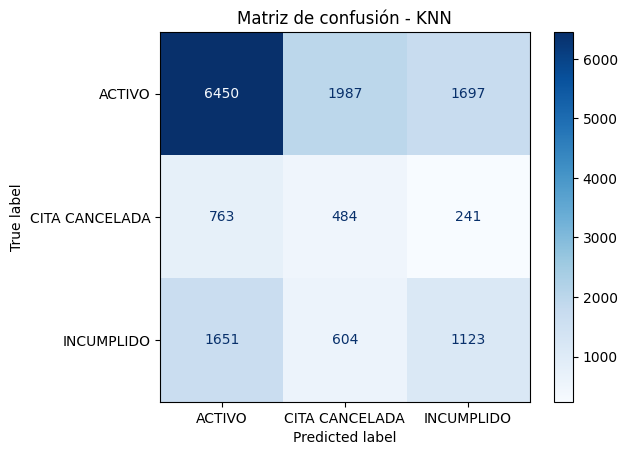

In [74]:
# Predicciones de KNN mediante validación cruzada
Y_pred_KNN = cross_val_predict(modeloKNN, X, Y, cv=cv)

# Matriz de confusión
matriz_KNN = confusion_matrix(Y, Y_pred_KNN)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_KNN, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - KNN')
plt.show()

In [75]:
# Guardar los resultados de KNN para la comparación
comparacion_CV['KNN'] = scoresKNN['test_f1']
comparacion_CV

,Tree,RF,KNN
0,0.462433,0.462782,0.424547
1,0.417139,0.451154,0.416780
2,0.433890,0.474599,0.427904
3,0.439336,0.454708,0.407933
4,0.413727,0.417695,0.389509
5,0.410417,0.428118,0.400078
6,0.410981,0.420885,0.407118
7,0.400823,0.409995,0.406601
8,0.414335,0.436565,0.416885
9,0.436304,0.443130,0.435272


## NN

In [76]:
# Configuración del modelo de Red Neuronal
from sklearn.neural_network import MLPClassifier

modelNN = MLPClassifier(hidden_layer_sizes=(30,), max_iter=500, random_state=42)

# Pipeline para Red Neuronal con balanceo combinado
modeloNN = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador_normalizado),
    ('clasificador', modelNN)
])

# Validación cruzada de la Red Neuronal
scoresNN = cross_validate(modeloNN, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

# Convertir resultados en DataFrame
scoresNN = pd.DataFrame(scoresNN)
scoresNN

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,24.222110,0.037267,0.554000,0.608963,0.427954,0.504231,0.446449,0.560118,0.427156,0.514724
1,21.413341,0.025818,0.556000,0.626519,0.433596,0.511783,0.456529,0.551180,0.439645,0.525129
2,17.219216,0.025275,0.552667,0.617259,0.431112,0.507261,0.454457,0.556045,0.437037,0.520422
3,18.703055,0.031228,0.526000,0.592296,0.429680,0.500442,0.450730,0.564453,0.423866,0.508399
4,22.240648,0.027951,0.503333,0.601111,0.395216,0.509970,0.411566,0.579715,0.393004,0.523117
5,22.166447,0.026132,0.532000,0.615481,0.405626,0.508113,0.401718,0.558733,0.395498,0.513602
6,21.044182,0.041749,0.519333,0.603185,0.412687,0.506911,0.432883,0.570154,0.411268,0.519147
7,19.373733,0.025585,0.554000,0.628222,0.429942,0.514716,0.451965,0.553996,0.435328,0.528113
8,24.106780,0.027034,0.505333,0.608667,0.403844,0.513353,0.427350,0.576017,0.403568,0.527417
9,17.186769,0.025356,0.556000,0.614667,0.430604,0.502824,0.443942,0.549276,0.429881,0.512592


In [77]:
# Promedios para evaluar overfitting y underfitting
scoresNN.mean()

,0
fit_time,20.767628
score_time,0.029340
test_accuracy,0.535867
train_accuracy,0.611637
test_precision,0.420026
train_precision,0.507960
test_recall,0.437759
train_recall,0.561969
test_f1,0.419625
train_f1,0.519266


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


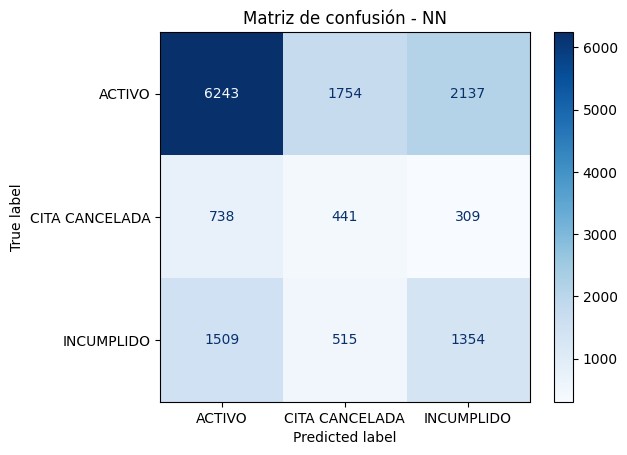

In [78]:
# Predicciones de NN mediante validación cruzada
Y_pred_NN = cross_val_predict(modeloNN, X, Y, cv=cv)

# Matriz de confusión
matriz_NN = confusion_matrix(Y, Y_pred_NN)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_NN, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - NN')
plt.show()

In [79]:
# Guardar los resultados de NN para la comparación
comparacion_CV['NN'] = scoresNN['test_f1']
comparacion_CV

,Tree,RF,KNN,NN
0,0.462433,0.462782,0.424547,0.427156
1,0.417139,0.451154,0.416780,0.439645
2,0.433890,0.474599,0.427904,0.437037
3,0.439336,0.454708,0.407933,0.423866
4,0.413727,0.417695,0.389509,0.393004
5,0.410417,0.428118,0.400078,0.395498
6,0.410981,0.420885,0.407118,0.411268
7,0.400823,0.409995,0.406601,0.435328
8,0.414335,0.436565,0.416885,0.403568
9,0.436304,0.443130,0.435272,0.429881


## SVM

In [80]:
# Configuración del modelo SVM
from sklearn.svm import SVC

modelSVM = SVC(kernel='rbf', C=1, random_state=42)

# Pipeline para SVM con balanceo combinado
modeloSVM = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador_normalizado),
    ('clasificador', modelSVM)
])

# Validación cruzada de SVM
scoresSVM = cross_validate(modeloSVM, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

# Convertir resultados en DataFrame
scoresSVM = pd.DataFrame(scoresSVM)
scoresSVM

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,16.299024,2.223977,0.596000,0.611037,0.450581,0.477167,0.461355,0.494672,0.454379,0.483592
1,16.077510,1.553360,0.602667,0.625778,0.458105,0.479245,0.463837,0.481855,0.460528,0.479559
2,15.987850,1.738748,0.602000,0.621556,0.455853,0.481167,0.461276,0.490415,0.458242,0.485091
3,16.357815,1.553558,0.600000,0.618148,0.453213,0.477828,0.456954,0.489840,0.452874,0.482478
4,15.899221,1.556124,0.568000,0.615556,0.405731,0.482015,0.410326,0.498022,0.407551,0.488573
5,19.096180,1.602450,0.564000,0.607630,0.410804,0.473637,0.413166,0.491871,0.410157,0.479089
6,15.738594,1.532345,0.566000,0.605259,0.421504,0.471352,0.429014,0.489528,0.423054,0.477082
7,16.663087,1.620065,0.568667,0.619407,0.411509,0.481599,0.416063,0.494470,0.413261,0.486827
8,15.618367,1.546504,0.588667,0.620963,0.423088,0.477409,0.421461,0.482102,0.421945,0.479484
9,16.302552,2.031914,0.594667,0.609852,0.442919,0.473563,0.447106,0.489454,0.444007,0.479573


In [81]:
# Promedios para evaluar overfitting y underfitting
scoresSVM.mean()

,0
fit_time,16.404020
score_time,1.695905
test_accuracy,0.585067
train_accuracy,0.615519
test_precision,0.433331
train_precision,0.477498
test_recall,0.438056
train_recall,0.490223
test_f1,0.434600
train_f1,0.482135


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


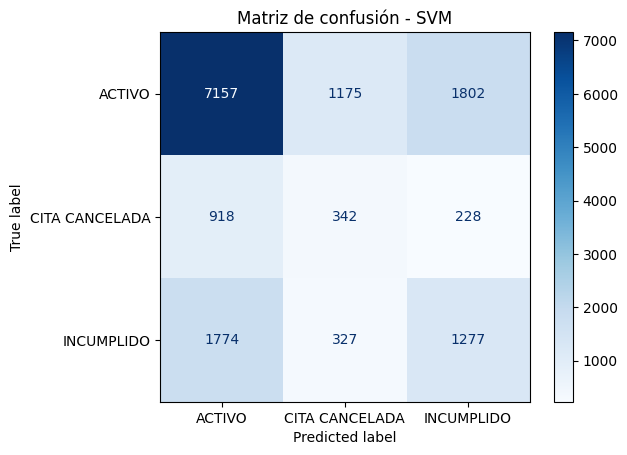

In [82]:
# Predicciones de SVM mediante validación cruzada
Y_pred_SVM = cross_val_predict(modeloSVM, X, Y, cv=cv)

# Matriz de confusión
matriz_SVM = confusion_matrix(Y, Y_pred_SVM)

# Visualización
ConfusionMatrixDisplay(
    confusion_matrix=matriz_SVM,
    display_labels=labelencoder.classes_
).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - SVM')
plt.show()

In [83]:
# Guardar los resultados de SVM para la comparación
comparacion_CV['SVM'] = scoresSVM['test_f1']
comparacion_CV

,Tree,RF,KNN,NN,SVM
0,0.462433,0.462782,0.424547,0.427156,0.454379
1,0.417139,0.451154,0.416780,0.439645,0.460528
2,0.433890,0.474599,0.427904,0.437037,0.458242
3,0.439336,0.454708,0.407933,0.423866,0.452874
4,0.413727,0.417695,0.389509,0.393004,0.407551
5,0.410417,0.428118,0.400078,0.395498,0.410157
6,0.410981,0.420885,0.407118,0.411268,0.423054
7,0.400823,0.409995,0.406601,0.435328,0.413261
8,0.414335,0.436565,0.416885,0.403568,0.421945
9,0.436304,0.443130,0.435272,0.429881,0.444007


## Regresión Logística

In [84]:
# Configuración del modelo de Regresión Logística
from sklearn.linear_model import LogisticRegression

modelLR = LogisticRegression(max_iter=1000, random_state=42)

# Pipeline para Regresión Logística con balanceo combinado
modeloLR = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador_normalizado),
    ('clasificador', modelLR)
])

# Validación cruzada de Regresión Logística
scoresLR = cross_validate(modeloLR, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

scoresLR = pd.DataFrame(scoresLR)
scoresLR

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,1.957585,0.034724,0.553333,0.538296,0.433647,0.419891,0.454705,0.436027,0.435613,0.419381
1,2.070206,0.037052,0.554000,0.549704,0.426510,0.422243,0.444462,0.433638,0.430449,0.421574
2,2.149991,0.034966,0.554667,0.549704,0.420859,0.420472,0.431411,0.433557,0.421620,0.421766
3,3.544788,0.037047,0.542000,0.551037,0.421012,0.417459,0.440406,0.427990,0.422400,0.418289
4,1.903985,0.035283,0.536000,0.546667,0.403472,0.423801,0.411237,0.440423,0.402593,0.424952
5,2.145431,0.037786,0.522667,0.537778,0.401132,0.422112,0.403682,0.438949,0.395134,0.420853
6,2.056331,0.076468,0.520667,0.537481,0.403645,0.423420,0.410985,0.443398,0.399340,0.423536
7,2.018219,0.035658,0.525333,0.547778,0.404693,0.425496,0.420263,0.443376,0.404894,0.427722
8,2.531858,0.040244,0.531333,0.548667,0.399796,0.423424,0.405395,0.439031,0.397469,0.425106
9,3.046741,0.034802,0.542000,0.547852,0.421036,0.426034,0.430461,0.442053,0.417773,0.425756


In [85]:
# Promedios para evaluar overfitting y underfitting
scoresLR.mean()

,0
fit_time,2.342514
score_time,0.040403
test_accuracy,0.538200
train_accuracy,0.545496
test_precision,0.413580
train_precision,0.422435
test_recall,0.425301
train_recall,0.437844
test_f1,0.412729
train_f1,0.422893


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


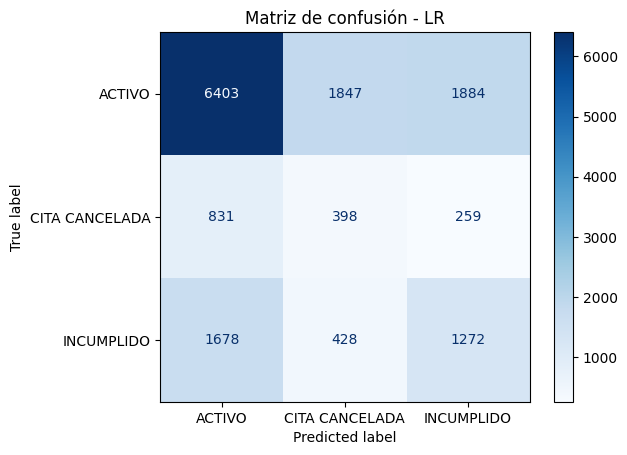

In [86]:
# Predicciones de LR mediante validación cruzada
Y_pred_LR = cross_val_predict(modeloLR, X, Y, cv=cv)

# Matriz de confusión
matriz_LR = confusion_matrix(Y, Y_pred_LR)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_LR, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - LR')
plt.show()

In [87]:
# Guardar los resultados de LR para la comparación
comparacion_CV['LR'] = scoresLR['test_f1']
comparacion_CV

,Tree,RF,KNN,NN,SVM,LR
0,0.462433,0.462782,0.424547,0.427156,0.454379,0.435613
1,0.417139,0.451154,0.416780,0.439645,0.460528,0.430449
2,0.433890,0.474599,0.427904,0.437037,0.458242,0.421620
3,0.439336,0.454708,0.407933,0.423866,0.452874,0.422400
4,0.413727,0.417695,0.389509,0.393004,0.407551,0.402593
5,0.410417,0.428118,0.400078,0.395498,0.410157,0.395134
6,0.410981,0.420885,0.407118,0.411268,0.423054,0.399340
7,0.400823,0.409995,0.406601,0.435328,0.413261,0.404894
8,0.414335,0.436565,0.416885,0.403568,0.421945,0.397469
9,0.436304,0.443130,0.435272,0.429881,0.444007,0.417773


## Baggin

In [88]:
# Configuración del modelo Bagging
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

modelBagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=10,min_samples_leaf=15,random_state=42),
    n_estimators=50, max_samples=0.8,random_state=42,n_jobs=-1
)

# Pipeline para Bagging con balanceo combinado
modeloBagging = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador),
    ('clasificador', modelBagging)
])

# Validación cruzada de Bagging
scoresBagging = cross_validate(modeloBagging, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

# Convertir resultados en DataFrame
scoresBagging = pd.DataFrame(scoresBagging)
scoresBagging

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,8.913858,0.095314,0.569333,0.615852,0.446068,0.495878,0.470816,0.528671,0.449246,0.502935
1,4.323920,0.093693,0.574000,0.621778,0.452114,0.498233,0.480381,0.527977,0.457841,0.505601
2,6.110815,0.084040,0.595333,0.628148,0.454771,0.500850,0.467509,0.525891,0.457748,0.507012
3,9.301648,0.744266,0.608000,0.640444,0.460675,0.510673,0.468180,0.532041,0.463429,0.518224
4,8.106530,0.173990,0.582667,0.641704,0.427772,0.512795,0.436306,0.532036,0.430792,0.520613
5,6.205686,0.086570,0.570000,0.620222,0.437312,0.499099,0.451193,0.529096,0.438062,0.504675
6,4.421178,0.100433,0.569333,0.625556,0.441209,0.500504,0.456715,0.528450,0.441930,0.507120
7,4.371997,0.152662,0.580000,0.636296,0.438982,0.507799,0.447246,0.530114,0.438669,0.514615
8,5.833408,0.102964,0.574667,0.632667,0.430977,0.503654,0.444360,0.526242,0.433709,0.509988
9,4.446813,0.094617,0.626000,0.631481,0.481847,0.500630,0.489411,0.521938,0.482632,0.506702


In [89]:
# Promedios para evaluar overfitting y underfitting
scoresBagging.mean()

,0
fit_time,6.203585
score_time,0.172855
test_accuracy,0.584933
train_accuracy,0.629415
test_precision,0.447173
train_precision,0.503011
test_recall,0.461212
train_recall,0.528246
test_f1,0.449406
train_f1,0.509748


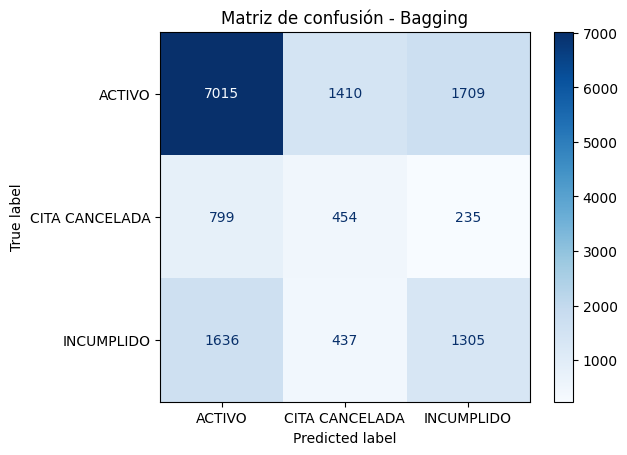

In [90]:
# Predicciones de Bagging mediante validación cruzada
Y_pred_Bagging = cross_val_predict(modeloBagging, X, Y, cv=cv)

# Matriz de confusión
matriz_Bagging = confusion_matrix(Y, Y_pred_Bagging)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_Bagging, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Bagging')
plt.show()

In [91]:
# Guardar resultados de Bagging
comparacion_CV['Bagging'] = scoresBagging['test_f1']
comparacion_CV

,Tree,RF,KNN,NN,SVM,LR,Bagging
0,0.462433,0.462782,0.424547,0.427156,0.454379,0.435613,0.449246
1,0.417139,0.451154,0.416780,0.439645,0.460528,0.430449,0.457841
2,0.433890,0.474599,0.427904,0.437037,0.458242,0.421620,0.457748
3,0.439336,0.454708,0.407933,0.423866,0.452874,0.422400,0.463429
4,0.413727,0.417695,0.389509,0.393004,0.407551,0.402593,0.430792
5,0.410417,0.428118,0.400078,0.395498,0.410157,0.395134,0.438062
6,0.410981,0.420885,0.407118,0.411268,0.423054,0.399340,0.441930
7,0.400823,0.409995,0.406601,0.435328,0.413261,0.404894,0.438669
8,0.414335,0.436565,0.416885,0.403568,0.421945,0.397469,0.433709
9,0.436304,0.443130,0.435272,0.429881,0.444007,0.417773,0.482632


## Boosting

In [92]:
# Configuración del modelo Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

modelGB = GradientBoostingClassifier(n_estimators=100,learning_rate=0.1, max_depth=3, random_state=42)

# Pipeline para Gradient Boosting con balanceo combinado
modeloGB = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador),
    ('clasificador', modelGB)
])

# Validación cruzada de Gradient Boosting
scoresGB = cross_validate(modeloGB, X, Y, cv=cv,scoring=scoring,return_train_score=True,return_estimator=False)

# Convertir resultados en DataFrame
scoresGB = pd.DataFrame(scoresGB)
scoresGB

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,4.505746,0.037323,0.584667,0.580000,0.460281,0.457796,0.484097,0.484585,0.465021,0.464283
1,5.482484,0.041648,0.578000,0.583778,0.461325,0.461323,0.493066,0.488022,0.468923,0.467321
2,4.428913,0.041061,0.581333,0.595111,0.444846,0.464073,0.460192,0.485891,0.450522,0.471028
3,4.542558,0.036197,0.590000,0.590889,0.459888,0.460069,0.481267,0.481759,0.467006,0.467004
4,5.631690,0.035736,0.563333,0.594074,0.427829,0.467370,0.443999,0.492851,0.431965,0.475237
5,4.422746,0.038196,0.568667,0.588000,0.430528,0.463418,0.441842,0.488661,0.432053,0.469412
6,5.293867,0.056255,0.565333,0.584444,0.435734,0.462970,0.453086,0.491548,0.439730,0.469631
7,4.689537,0.036631,0.546000,0.595556,0.420192,0.468044,0.439474,0.493025,0.423672,0.475751
8,4.589805,0.037114,0.557333,0.594963,0.425188,0.466465,0.441972,0.490348,0.429099,0.473895
9,5.632578,0.037097,0.590667,0.588963,0.458797,0.459111,0.477292,0.481368,0.463982,0.465762


In [93]:
# Promedios para evaluar overfitting y underfitting
scoresGB.mean()

,0
fit_time,4.921992
score_time,0.039726
test_accuracy,0.572533
train_accuracy,0.589578
test_precision,0.442461
train_precision,0.463064
test_recall,0.461629
train_recall,0.487806
test_f1,0.447197
train_f1,0.469932


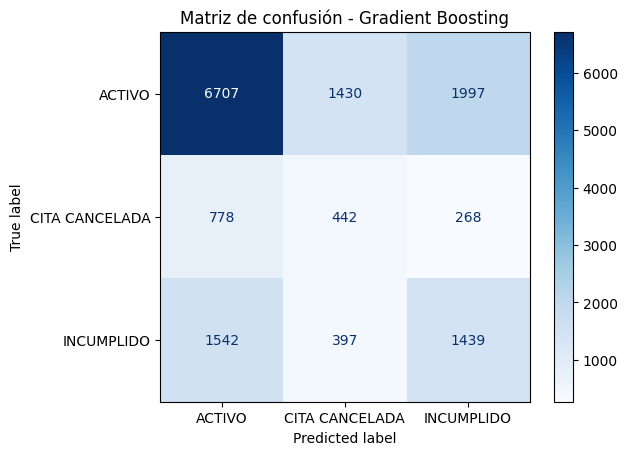

In [94]:
# Predicciones de Gradient Boosting mediante validación cruzada
Y_pred_GB = cross_val_predict(modeloGB, X, Y, cv=cv)

# Matriz de confusión
matriz_GB = confusion_matrix(Y, Y_pred_GB)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_GB,display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Gradient Boosting')
plt.show()

In [95]:
# Guardar resultados de Gradient Boosting
comparacion_CV['GB'] = scoresGB['test_f1']
comparacion_CV

,Tree,RF,KNN,NN,SVM,LR,Bagging,GB
0,0.462433,0.462782,0.424547,0.427156,0.454379,0.435613,0.449246,0.465021
1,0.417139,0.451154,0.416780,0.439645,0.460528,0.430449,0.457841,0.468923
2,0.433890,0.474599,0.427904,0.437037,0.458242,0.421620,0.457748,0.450522
3,0.439336,0.454708,0.407933,0.423866,0.452874,0.422400,0.463429,0.467006
4,0.413727,0.417695,0.389509,0.393004,0.407551,0.402593,0.430792,0.431965
5,0.410417,0.428118,0.400078,0.395498,0.410157,0.395134,0.438062,0.432053
6,0.410981,0.420885,0.407118,0.411268,0.423054,0.399340,0.441930,0.439730
7,0.400823,0.409995,0.406601,0.435328,0.413261,0.404894,0.438669,0.423672
8,0.414335,0.436565,0.416885,0.403568,0.421945,0.397469,0.433709,0.429099
9,0.436304,0.443130,0.435272,0.429881,0.444007,0.417773,0.482632,0.463982


## Votación "Hard"

In [96]:
# Configuración del modelo Voting
from sklearn.ensemble import VotingClassifier

modelVoting = VotingClassifier(estimators=[('tree', modelTree),('bagging', modelBagging), ('gb', modelGB)], voting='hard')

# Pipeline para Voting con balanceo combinado
modeloVoting = Pipeline([
    ('undersampling', under),
    ('balanceo', smote),
    ('transformacion', transformador),
    ('clasificador', modelVoting)
])

# Validación cruzada de Voting
scoresVoting = cross_validate(modeloVoting, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)

scoresVoting = pd.DataFrame(scoresVoting)
scoresVoting

,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
0,9.402677,0.131394,0.574667,0.602741,0.456017,0.486166,0.482691,0.519502,0.459075,0.492689
1,8.828066,0.122132,0.558000,0.603259,0.443958,0.486679,0.472492,0.518475,0.447169,0.491561
2,7.748848,0.188249,0.580000,0.603630,0.446829,0.479399,0.463284,0.505533,0.450389,0.484623
3,9.198452,0.118123,0.604000,0.621185,0.458186,0.488791,0.466865,0.507855,0.461416,0.494999
4,9.061805,0.119363,0.576667,0.635704,0.420899,0.504867,0.428151,0.523167,0.423625,0.512205
5,8.003343,0.176362,0.567333,0.609481,0.427879,0.484883,0.437114,0.510287,0.428175,0.489823
6,8.518445,0.117127,0.567333,0.614593,0.442262,0.493597,0.460201,0.523132,0.443584,0.498835
7,9.307743,0.118193,0.580667,0.633407,0.430785,0.500022,0.437187,0.516171,0.430803,0.505907
8,8.444295,0.176588,0.569333,0.622370,0.429430,0.494526,0.444950,0.518704,0.432185,0.500855
9,8.116709,0.119424,0.617333,0.624519,0.473849,0.492178,0.480660,0.511884,0.474898,0.498588


In [97]:
# Promedios para evaluar overfitting y underfitting
scoresVoting.mean()

,0
fit_time,8.663038
score_time,0.138695
test_accuracy,0.579533
train_accuracy,0.617089
test_precision,0.443009
train_precision,0.491111
test_recall,0.457360
train_recall,0.515471
test_f1,0.445132
train_f1,0.497008


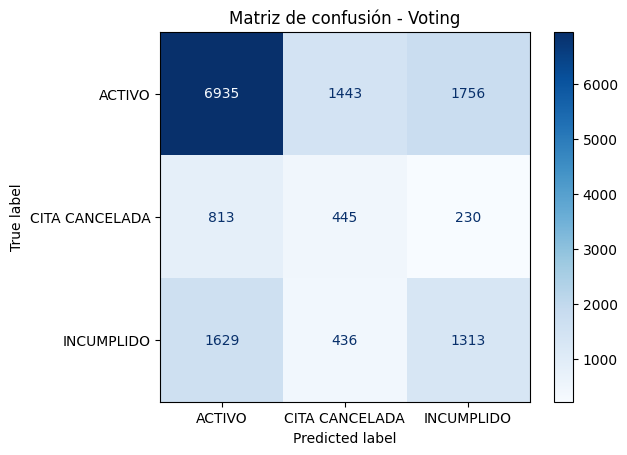

In [98]:
# Predicciones de Voting mediante validación cruzada
Y_pred_Voting = cross_val_predict(modeloVoting, X, Y, cv=cv)

# Matriz de confusión
matriz_Voting = confusion_matrix(Y, Y_pred_Voting)

# Visualización
ConfusionMatrixDisplay(confusion_matrix=matriz_Voting, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Voting')
plt.show()


In [99]:
# Guardar resultados del ensamble Voting
comparacion_CV['Voting'] = scoresVoting['test_f1']

comparacion_CV

,Tree,RF,KNN,NN,SVM,LR,Bagging,GB,Voting
0,0.462433,0.462782,0.424547,0.427156,0.454379,0.435613,0.449246,0.465021,0.459075
1,0.417139,0.451154,0.416780,0.439645,0.460528,0.430449,0.457841,0.468923,0.447169
2,0.433890,0.474599,0.427904,0.437037,0.458242,0.421620,0.457748,0.450522,0.450389
3,0.439336,0.454708,0.407933,0.423866,0.452874,0.422400,0.463429,0.467006,0.461416
4,0.413727,0.417695,0.389509,0.393004,0.407551,0.402593,0.430792,0.431965,0.423625
5,0.410417,0.428118,0.400078,0.395498,0.410157,0.395134,0.438062,0.432053,0.428175
6,0.410981,0.420885,0.407118,0.411268,0.423054,0.399340,0.441930,0.439730,0.443584
7,0.400823,0.409995,0.406601,0.435328,0.413261,0.404894,0.438669,0.423672,0.430803
8,0.414335,0.436565,0.416885,0.403568,0.421945,0.397469,0.433709,0.429099,0.432185
9,0.436304,0.443130,0.435272,0.429881,0.444007,0.417773,0.482632,0.463982,0.474898


# 5. Selecion del modelo:


In [100]:
comparacion_CV

,Tree,RF,KNN,NN,SVM,LR,Bagging,GB,Voting
0,0.462433,0.462782,0.424547,0.427156,0.454379,0.435613,0.449246,0.465021,0.459075
1,0.417139,0.451154,0.416780,0.439645,0.460528,0.430449,0.457841,0.468923,0.447169
2,0.433890,0.474599,0.427904,0.437037,0.458242,0.421620,0.457748,0.450522,0.450389
3,0.439336,0.454708,0.407933,0.423866,0.452874,0.422400,0.463429,0.467006,0.461416
4,0.413727,0.417695,0.389509,0.393004,0.407551,0.402593,0.430792,0.431965,0.423625
5,0.410417,0.428118,0.400078,0.395498,0.410157,0.395134,0.438062,0.432053,0.428175
6,0.410981,0.420885,0.407118,0.411268,0.423054,0.399340,0.441930,0.439730,0.443584
7,0.400823,0.409995,0.406601,0.435328,0.413261,0.404894,0.438669,0.423672,0.430803
8,0.414335,0.436565,0.416885,0.403568,0.421945,0.397469,0.433709,0.429099,0.432185
9,0.436304,0.443130,0.435272,0.429881,0.444007,0.417773,0.482632,0.463982,0.474898


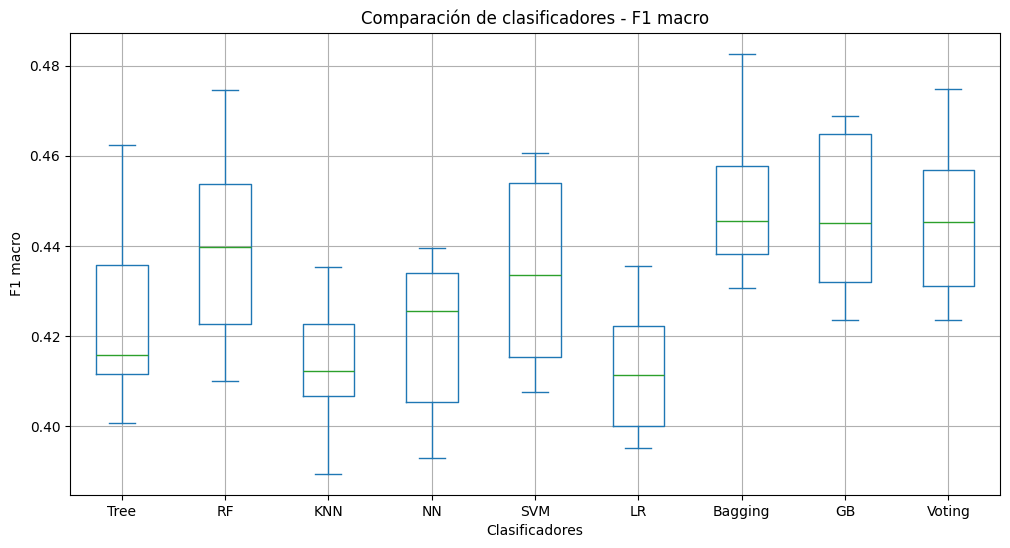

In [101]:
# Comparación de clasificadores mediante F1 macro
comparacion_CV.plot(kind='box',figsize=(12, 6), grid=True)

plt.title('Comparación de clasificadores - F1 macro')
plt.ylabel('F1 macro')
plt.xlabel('Clasificadores')
plt.show()

In [102]:
# Métricas por clase - Gradient Boosting
from sklearn.metrics import classification_report

print(classification_report(
    Y,
    Y_pred_GB,
    target_names=['ACTIVO', 'CITA CANCELADA', 'INCUMPLIDO'],
    zero_division=0
))

                precision    recall  f1-score   support

        ACTIVO       0.74      0.66      0.70     10134
CITA CANCELADA       0.19      0.30      0.24      1488
    INCUMPLIDO       0.39      0.43      0.41      3378

      accuracy                           0.57     15000
     macro avg       0.44      0.46      0.45     15000
  weighted avg       0.61      0.57      0.59     15000



Se evaluaron **nueve** clasificadores mediante validación cruzada estratificada de diez particiones, utilizando una muestra de 15.000 registros y una estrategia de balanceo combinado aplicada exclusivamente a los datos de entrenamiento.

Bagging obtuvo el mayor F1 macro promedio (44,94 %), seguido de Gradient Boosting (44,72 %). Sin embargo, considerando que el objetivo principal de la IPS es anticipar las citas incumplidas, se priorizó el recall de la clase INCUMPLIDO.

**Gradient Boosting se selecciona como modelo candidato**, al presentar el mayor recall de INCUMPLIDO (42,60 %) entre los principales clasificadores, un F1 macro competitivo y una diferencia de 2,27 puntos porcentuales entre entrenamiento y validación.

La selección queda sujeta a una evaluación final independiente, reconociendo las limitaciones del modelo para identificar la totalidad de los incumplimientos.

# 6. Modelo final con todos los datos

In [109]:
# Separación de la base completa para la evaluación final 70-30
from sklearn.model_selection import train_test_split

X_final = data.drop(columns=[objetivo])
Y_final = labelencoder.transform(data[objetivo])

X_train, X_test, Y_train, Y_test = train_test_split(X_final, Y_final, test_size=0.30, stratify=Y_final, random_state=42)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

Registros de entrenamiento: 39487
Registros de prueba: 16924


In [110]:
# Entrenamiento del modelo final - Gradient Boosting
modeloGB.fit(X_train, Y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('undersampling',
                 RandomUnderSampler(random_state=42,
                                    sampling_strategy=<function estrategia_undersampling at 0x7c92c99f0ea0>)),
                ('balanceo',
                 SMOTENC(categorical_features=['sexopaciente', 'turno_doble',
                                               'grupo_pym', 'programacronico',
                                               'funcionalidad', 'rotulo',
                                               'municipiosede',
                                               'poblacion_vulnerable',
                                               'grupo_convenionombre',
                                               'grupo_municipio', 'dia_...
                                                  ['sexopaciente',
                                                   'turno_doble',
                                                   'grupo_pym']),
                                                 ('multiclase',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['programacronico',
                                                   'funcionalidad', 'rotulo',
                                                   'municipiosede',
                                                   'poblacion_vulnerable',
                                                   'grupo_convenionombre',
                                                   'grupo_municipio',
                                                   'dia_semana', 'mes',
                                                   'grupo_horacita',
                                                   'grupo_edad',
                                                   'grupo_codigocups'])])),
                ('clasificador', GradientBoostingClassifier(random_state=42))])

In [105]:
# Predicciones del modelo final - Gradient Boosting
Y_pred_final = modeloGB.predict(X_test)

In [106]:
# Evaluación del modelo final - Gradient Boosting
from sklearn.metrics import classification_report

print(classification_report(
    Y_test,
    Y_pred_final,
    target_names=['ACTIVO', 'CITA CANCELADA', 'INCUMPLIDO'],
    zero_division=0
))

                precision    recall  f1-score   support

        ACTIVO       0.75      0.68      0.71     11434
CITA CANCELADA       0.22      0.32      0.26      1679
    INCUMPLIDO       0.39      0.41      0.40      3811

      accuracy                           0.59     16924
     macro avg       0.45      0.47      0.46     16924
  weighted avg       0.61      0.59      0.60     16924



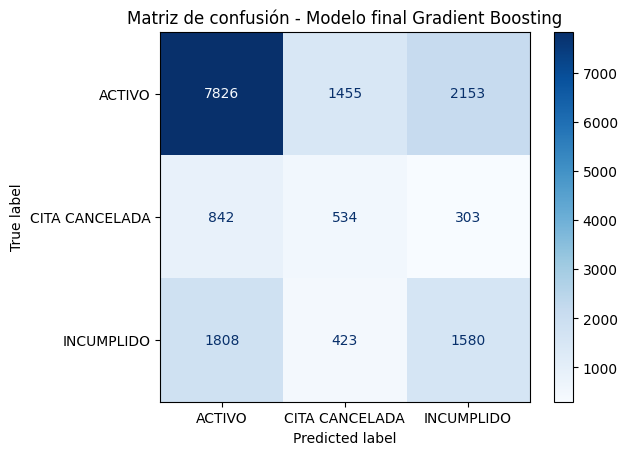

In [107]:
# Matriz de confusión del modelo final - Gradient Boosting
matriz_final = confusion_matrix(Y_test, Y_pred_final)

ConfusionMatrixDisplay( confusion_matrix=matriz_final, display_labels=labelencoder.classes_).plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Modelo final Gradient Boosting')
plt.show()

## **Evaluación del modelo final**

El modelo Gradient Boosting se entrenó utilizando el 70 % de la base original (39.487 registros), mediante un Pipeline que incorporó balanceo combinado y transformación de variables predictoras. Posteriormente, se evaluó sobre el 30 % restante (16.924 registros), conservando la distribución original de las clases.

El modelo obtuvo un F1 macro aproximado de 0,46. Para la clase INCUMPLIDO, identificó correctamente 1.580 de las 3.811 citas reales, alcanzando un recall del 41,46 % y una precisión del 39,15 %.

Si bien Gradient Boosting presentó resultados competitivos frente a los demás clasificadores evaluados, su capacidad para anticipar incumplimientos y cancelaciones continuó siendo limitada.

Los resultados evidencian que, pese a la evaluación de nueve clasificadores, los ajustes de hiperparámetros y las diferentes estrategias de balanceo implementadas, no se alcanzó un desempeño predictivo suficientemente alto para identificar de manera confiable los estados de las citas médicas.

Este hallazgo constituye un resultado relevante del proceso de modelamiento y permite reconocer las limitaciones de la información disponible para el problema de clasificación planteado.

# Guardar el modelo

In [108]:
# Guardar el modelo final y los elementos necesarios para la predicción
import pickle

filename = 'modelo_citas_medicas.pkl'
variables = X_train.columns._values

with open(filename, 'wb') as archivo:
    pickle.dump([modeloGB, labelencoder, variables], archivo)

print("Modelo guardado correctamente.")

Modelo guardado correctamente.
